# **Оценка стоимости подержанного автомобиля**

Датасет: [US Used Cars Dataset (Kaggle)](https://www.kaggle.com/datasets/ananaymital/us-used-cars-dataset) — 3 млн объявлений о продаже автомобилей на сайте CarGurus (США, 2020 г.).

In [15]:
import os
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения

pd.set_option('display.max_columns', 60)

# 0. Постановка задачи

Предположим, что мы хотим продать (или купить) автомобиль и хотим понять его справедливую рыночную цену — чтобы не продешевить (или не переплатить).

У нас есть объявления о продаже автомобилей в США. Для каждого автомобиля известны его характеристики: год выпуска, пробег, марка, тип кузова, мощность двигателя, тип топлива и коробки передач, привод, габариты, расход топлива, был ли автомобиль в ДТП, новый он или подержанный, рейтинг продавца, координаты дилера и т.д. — и **цена** в долларах.

**Требуется по характеристикам автомобиля предсказать его цену `price`.**

Целевой признак `price` — количественный (непрерывный), поэтому это **задача восстановления регрессии** (обучение с учителем).

# 1. Читаем данные

Исходный файл `used_cars_data.csv` весит **~10 ГБ** (3 000 040 строк × 66 столбцов), крайне большой, поэтому:


1. читаем файл **по кускам** (`chunksize`) и не все столбцы, а **только выбранные** — 31 из 66 (параметр `usecols`, список `USECOLS` ниже);
2. из каждого куска берем **случайную подвыборку 3%** — получается ≈90 тыс. объектов. Этого более чем достаточно для обучения, а метод ближайших соседей на 3 млн объектов работал бы очень долго;
3. результат сохраняем в `used_cars_sample.csv`, чтобы при повторном запуске ноутбука не читать 10 ГБ заново (первый запуск занимает ~5 минут).

### Как выбирал столбцы

Сначала прочитаем первые 200 тыс. строк файла со **всеми** столбцами и для каждого посчитаем долю пропусков, число уникальных значений и долю самого частого значения.

In [16]:
# Первые 200 тыс. строк со всеми 66 столбцами — по ним выбираем, какие столбцы брать
preview = pd.read_csv('used_cars_data.csv', nrows=200_000, low_memory=False)

columns_info = pd.DataFrame({
    'пропуски, %':       (preview.isna().mean() * 100).round(1),
    'уникальных':        preview.nunique(),
    'частое значение, %': (preview.apply(lambda s: s.value_counts(normalize=True).max()) * 100).round(1),
}).sort_values('пропуски, %', ascending=False)

with pd.option_context('display.max_rows', 100):
    display(columns_info)

,"пропуски, %",уникальных,"частое значение, %"
vehicle_damage_category,100.0,0,NaN
combine_fuel_economy,100.0,0,NaN
is_certified,100.0,0,NaN
bed,99.4,3,58.1
cabin,98.3,4,72.7
is_oemcpo,94.0,1,100.0
is_cpo,91.4,1,100.0
bed_height,89.9,1,100.0
bed_length,89.9,68,17.7
owner_count,46.8,13,69.0


Также проверим: связаны ли между собой `fleet` (был в автопарке компании) и `isCab` (был такси), и чем является `listed_date` (дата публикации объявления):

In [17]:
used = preview[~preview['is_new']]
display(pd.crosstab(used['fleet'], used['isCab']))

# дата публикации + сколько дней объявление висит на сайте
(pd.to_datetime(preview['listed_date']) + pd.to_timedelta(preview['daysonmarket'], unit='D')).agg(['min', 'max'])

isCab,False,True
fleet,,
False,95075,0
True,2748,11418


min   2020-09-09
max   2020-09-17
dtype: datetime64[us]

По этим таблицам и по смыслу признаков **берем** 31 столбец, а **не берем** 35:
- идентификаторы и ссылки, не несущие информации о цене: `vin`, `listing_id`, `sp_id`, `sp_name`, `trimId`, `main_picture_url`;
- `description` — свободный текст объявления (медиана ≈ 2 500 символов): в основном реклама дилера и перечень комплектации. Чтобы его использовать, нужна обработка текста(Н.Ю. Золотых сказал пока пропустить)
- почти пустые столбцы: `vehicle_damage_category`, `combine_fuel_economy`, `is_certified` (100% пропусков), `bed`, `cabin`, `is_oemcpo`, `is_cpo`, `bed_height`, `bed_length` (90–99% пропусков);
- `theft_title` (машина числилась в угоне) — встречается у 0.3% подержанных машин;
- `isCab` — почти полный дубль `fleet`: каждая машина с `isCab = True` имеет и `fleet = True` (`fleet` шире на ≈ 2.7 тыс. машин), а эффект у них одинаковый;
- дублирующие другие признаки: `power` и `torque` (строки вида `'177 hp @ 5,750 RPM'` — мощность уже есть в `horsepower`), `transmission_display`, `wheel_system_display`, `engine_type` (дублируют `transmission`, `wheel_system`, `engine_cylinders`), `franchise_make` (марка, которую продает дилер совпадает с `make_name`, `city`, `dealer_zip` (местоположение уже задано координатами), `listed_date` (признак полностью дублирует `daysonmarket`);
- размеры салона: `front_legroom`, `back_legroom`;
- цвет: `exterior_color`, `interior_color` (6–7.5 тыс. вариантов написания), `listing_color` (15 базовых цветов);
- признаки с сотнями и тысячами уникальных значений, которые трудно закодировать: `model_name`, `trim_name`.

In [18]:
DATA_PATH   = 'used_cars_data.csv'    # полный датасет с Kaggle 
SAMPLE_PATH = 'used_cars_sample.csv'  # кэш случайной подвыборки

USECOLS = ['price', 'year', 'mileage', 'horsepower', 'engine_displacement', 'engine_cylinders',
           'city_fuel_economy', 'highway_fuel_economy', 'fuel_tank_volume',
           'length', 'width', 'height', 'wheelbase', 'maximum_seating',
           'daysonmarket', 'owner_count', 'seller_rating', 'latitude', 'longitude',
           'make_name', 'body_type', 'fuel_type', 'transmission', 'wheel_system',
           'is_new', 'has_accidents', 'frame_damaged', 'fleet', 'salvage', 'franchise_dealer',
           'major_options']

if os.path.exists(SAMPLE_PATH):
    data_raw = pd.read_csv(SAMPLE_PATH, low_memory=False)
else:
    rng = np.random.default_rng(42)
    parts = []
    for chunk in pd.read_csv(DATA_PATH, usecols=USECOLS, chunksize=200_000, low_memory=False):
        parts.append(chunk[rng.random(len(chunk)) < 0.03])
    data_raw = pd.concat(parts, ignore_index=True)[USECOLS]
    data_raw.to_csv(SAMPLE_PATH, index=False)

In [19]:
data_raw.shape

(89836, 31)

In [20]:
data_raw.sample(20)

,price,year,mileage,horsepower,engine_displacement,engine_cylinders,city_fuel_economy,highway_fuel_economy,fuel_tank_volume,length,width,height,wheelbase,maximum_seating,daysonmarket,owner_count,seller_rating,latitude,longitude,make_name,body_type,fuel_type,transmission,wheel_system,is_new,has_accidents,frame_damaged,fleet,salvage,franchise_dealer,major_options
87652,17995.0,2016,51082.0,182.0,2500.0,I4,27.0,39.0,18 gal,191.9 in,72 in,57.8 in,109.3 in,5 seats,9,2.0,NaN,36.6834,-121.6530,Nissan,Sedan,Gasoline,A,FWD,False,False,False,False,False,False,"['Sunroof/Moonroof', 'Navigation System', 'All..."
26368,51801.0,2019,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,231,NaN,4.331797,36.1070,-80.0617,RAM,Pickup Truck,NaN,A,NaN,True,NaN,NaN,NaN,NaN,True,"['Steel Wheels', 'Bluetooth', 'Dual Rear Wheel..."
35304,29994.0,2020,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,3.875000,31.9867,-81.1318,Nissan,Pickup Truck,NaN,A,NaN,True,NaN,NaN,NaN,NaN,True,NaN
73504,18097.0,2020,NaN,138.0,1400.0,I4,26.0,34.0,12.2 gal,159.8 in,68.3 in,59.7 in,99.4 in,5 seats,1,NaN,4.842105,32.5613,-97.3195,Chevrolet,Hatchback,Gasoline,A,FWD,True,NaN,NaN,NaN,NaN,True,"['Alloy Wheels', 'Backup Camera', 'Android Aut..."
12202,11703.0,2016,70098.0,130.0,1800.0,I4,29.0,38.0,13.2 gal,182.5 in,69.3 in,58.9 in,106.3 in,5 seats,15,2.0,3.045455,41.5991,-87.5826,Nissan,Sedan,Gasoline,CVT,FWD,False,False,False,False,False,True,"['Alloy Wheels', 'Bluetooth', 'Backup Camera',..."
68286,45778.0,2020,5.0,381.0,5700.0,V8,13.0,17.0,26.4 gal,228.9 in,79.9 in,76.4 in,145.7 in,6 seats,1,NaN,4.428571,33.2883,-111.7910,Toyota,Pickup Truck,Gasoline,A,4WD,True,NaN,NaN,NaN,NaN,True,"['Navigation System', 'Bluetooth', 'Backup Cam..."
8194,16933.0,2019,25500.0,132.0,1800.0,I4,28.0,35.0,13.2 gal,183.1 in,69.9 in,57.3 in,106.3 in,5 seats,40,1.0,4.111111,42.2912,-71.8031,Toyota,Sedan,Gasoline,CVT,FWD,False,False,False,False,False,True,"['Alloy Wheels', 'Backup Camera']"
15990,16997.0,2019,46886.0,283.0,3600.0,V6,16.0,24.0,21.1 gal,192.4 in,83.7 in,66.6 in,113.8 in,7 seats,22,1.0,2.857143,41.8860,-87.6310,Dodge,SUV / Crossover,Gasoline,A,AWD,False,False,False,True,False,False,"['Leather Seats', 'Alloy Wheels', 'Bluetooth',..."
77968,43620.0,2021,1.0,280.0,3500.0,V6,19.0,28.0,19.5 gal,205.2 in,92.3 in,69.6 in,118.1 in,8 seats,23,NaN,4.160000,38.7424,-121.2510,Honda,Minivan,Gasoline,A,FWD,True,NaN,NaN,NaN,NaN,True,NaN
27354,15990.0,2017,37236.0,138.0,1400.0,I4,25.0,33.0,14 gal,168.4 in,69.9 in,65.3 in,100.6 in,5 seats,7,1.0,4.769231,42.9253,-83.9881,Buick,SUV / Crossover,Gasoline,A,FWD,False,False,False,False,False,True,"['Navigation System', 'Alloy Wheels', 'Bluetoo..."


In [21]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 89836 entries, 0 to 89835
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price                 89836 non-null  float64
 1   year                  89836 non-null  int64  
 2   mileage               85589 non-null  float64
 3   horsepower            84669 non-null  float64
 4   engine_displacement   84669 non-null  float64
 5   engine_cylinders      86759 non-null  str    
 6   city_fuel_economy     75218 non-null  float64
 7   highway_fuel_economy  75218 non-null  float64
 8   fuel_tank_volume      85087 non-null  str    
 9   length                85087 non-null  str    
 10  width                 85087 non-null  str    
 11  height                85087 non-null  str    
 12  wheelbase             85087 non-null  str    
 13  maximum_seating       85087 non-null  str    
 14  daysonmarket          89836 non-null  int64  
 15  owner_count           44578 no

Описание признаков:

| Признак | Описание | Тип |
|---|---|---|
| `price` | цена, $ (**целевой**) | количественный |
| `year` | год выпуска | количественный (дискретный) |
| `mileage` | пробег, мили | количественный |
| `horsepower` | мощность, л.с. | количественный |
| `engine_displacement` | объем двигателя, см³ | количественный |
| `engine_cylinders` | конфигурация двигателя (`'I4'`, `'V6'`, …) → число цилиндров | количественный (дискретный) |
| `city_fuel_economy`, `highway_fuel_economy` | расход топлива в городе / на трассе, миль на галлон | количественный |
| `fuel_tank_volume` | объем бака, галлоны | количественный |
| `length`, `width`, `height`, `wheelbase` | габариты и колесная база, дюймы | количественный |
| `maximum_seating` | число мест | количественный (дискретный) |
| `daysonmarket` | сколько дней объявление висит на сайте | количественный |
| `owner_count` | число предыдущих владельцев | количественный (дискретный) |
| `seller_rating` | рейтинг продавца (1–5) | количественный |
| `latitude`, `longitude` | координаты дилера | количественный |
| `make_name` | марка | номинальный |
| `body_type` | тип кузова | номинальный |
| `fuel_type` | тип топлива | номинальный |
| `transmission` | коробка передач (`A` — автомат, `M` — механика, `CVT` — вариатор, `Dual Clutch`) | номинальный |
| `wheel_system` | привод (`FWD`, `RWD`, `AWD`, `4WD`, `4X2`) | номинальный |
| `is_new` | новый автомобиль | бинарный |
| `has_accidents` | был в ДТП | бинарный (с пропусками) |
| `frame_damaged` | повреждена рама | бинарный (с пропусками) |
| `fleet` | был в автопарке компании (каршеринг, прокат, такси, …) | бинарный (с пропусками) |
| `salvage` | восстановлен после тотальной аварии (*salvage title*) | бинарный (с пропусками) |
| `major_options` | список опций (`['Sunroof/Moonroof', 'Heated Seats', …]`) → 11 бинарных признаков `opt_*` | бинарные (с пропусками) |
| `franchise_dealer` | продавец — официальный дилер | бинарный |

Часть количественных признаков записана строками с единицами измерения (`'183.1 in'`, `'26 gal'`, `'5 seats'`), а пропуски в них закодированы как `'--'`. Сделаем из строк числа:

In [22]:
data_raw[['length', 'fuel_tank_volume', 'maximum_seating', 'engine_cylinders']].head()

,length,fuel_tank_volume,maximum_seating,engine_cylinders
0,166.9 in,13.2 gal,4 seats,I4
1,183.3 in,15.9 gal,5 seats,I4
2,192.1 in,27.6 gal,5 seats,I6
3,184.9 in,22.5 gal,5 seats,V6
4,204.3 in,19.4 gal,8 seats,V6


In [23]:
for col in ['length', 'width', 'height', 'wheelbase', 'fuel_tank_volume', 'maximum_seating']:
    data_raw[col] = pd.to_numeric(data_raw[col].str.extract(r'(\d+\.?\d*)')[0], errors='coerce')

# 'I4' -> 4, 'V6 Flex Fuel Vehicle' -> 6, 'W12' -> 12
data_raw['engine_cylinders'] = pd.to_numeric(data_raw['engine_cylinders'].str.extract(r'(\d+)')[0], errors='coerce')

data_raw[['length', 'fuel_tank_volume', 'maximum_seating', 'engine_cylinders']].head()

,length,fuel_tank_volume,maximum_seating,engine_cylinders
0,166.9,13.2,4.0,4.0
1,183.3,15.9,5.0,4.0
2,192.1,27.6,5.0,6.0
3,184.9,22.5,5.0,6.0
4,204.3,19.4,8.0,6.0


### Опции

`major_options` — строка со списком опций автомобиля. Для 11 опций заведем бинарный признак: 1 — опция есть в списке, 0 — нет. Если список опций не заполнен, признак оставим пропущенным — его заполним вместе с остальными пропусками (п. 5).

In [24]:
OPTIONS = {'Sunroof/Moonroof':        'opt_sunroof',
           'Navigation System':       'opt_navigation',
           'Leather Seats':           'opt_leather_seats',
           'Heated Seats':            'opt_heated_seats',
           'Blind Spot Monitoring':   'opt_blind_spot',
           'Adaptive Cruise Control': 'opt_adaptive_cruise',
           'Remote Start':            'opt_remote_start',
           'Tow Package':             'opt_tow_package',
           'Premium Package':         'opt_premium_package',
           'Parking Sensors':         'opt_parking_sensors',
           'Steel Wheels':            'opt_steel_wheels'}

for option, col in OPTIONS.items():
    has_option = data_raw['major_options'].str.contains(f"'{option}'", regex=False)
    data_raw[col] = has_option.astype(float).where(data_raw['major_options'].notna())   # пропуск остается пропуском
data_raw = data_raw.drop(columns='major_options')

data_raw[list(OPTIONS.values())].agg(['mean', lambda s: s.isna().mean()]).set_axis(['доля с опцией', 'доля пропусков']).round(3)

,opt_sunroof,opt_navigation,opt_leather_seats,opt_heated_seats,opt_blind_spot,opt_adaptive_cruise,opt_remote_start,opt_tow_package,opt_premium_package,opt_parking_sensors,opt_steel_wheels
доля с опцией,0.331,0.365,0.278,0.427,0.268,0.166,0.319,0.046,0.060,0.186,0.087
доля пропусков,0.068,0.068,0.068,0.068,0.068,0.068,0.068,0.068,0.068,0.068,0.068


Бинарные признаки без пропусков `is_new`, `franchise_dealer` сразу заменим на 0/1. Номинальные признаки переведем в специальный тип `category`:

In [25]:
data_raw['is_new'] = data_raw['is_new'].astype(int)
data_raw['franchise_dealer'] = data_raw['franchise_dealer'].astype(int)

cat_features = ['make_name', 'body_type', 'fuel_type', 'transmission', 'wheel_system',
                'has_accidents', 'frame_damaged', 'fleet', 'salvage']
for col in cat_features:
    data_raw[col] = data_raw[col].astype('category')

data_raw.dtypes

price                    float64
year                       int64
mileage                  float64
horsepower               float64
engine_displacement      float64
engine_cylinders         float64
city_fuel_economy        float64
highway_fuel_economy     float64
fuel_tank_volume         float64
length                   float64
width                    float64
height                   float64
wheelbase                float64
maximum_seating          float64
daysonmarket               int64
owner_count              float64
seller_rating            float64
latitude                 float64
longitude                float64
make_name               category
body_type               category
fuel_type               category
transmission            category
wheel_system            category
is_new                     int64
has_accidents           category
frame_damaged           category
fleet                   category
salvage                 category
franchise_dealer           int64
opt_sunroo

Пропусков достаточно много, просто удалить строки не поулчится

In [26]:
data_raw.isnull().sum()

price                       0
year                        0
mileage                  4247
horsepower               5167
engine_displacement      5167
engine_cylinders         3077
city_fuel_economy       14618
highway_fuel_economy    14618
fuel_tank_volume         4791
length                   4759
width                    4760
height                   4760
wheelbase                4759
maximum_seating          4759
daysonmarket                0
owner_count             45258
seller_rating            1220
latitude                    0
longitude                   0
make_name                   0
body_type                 386
fuel_type                2537
transmission             1876
wheel_system             4410
is_new                      0
has_accidents           42538
frame_damaged           42538
fleet                   42538
salvage                 42538
franchise_dealer            0
opt_sunroof              6080
opt_navigation           6080
opt_leather_seats        6080
opt_heated

# 2. Разбиваем данные на обучающую и тестовую выборки

Разбиваем **до** всякого анализа и предобработки: все статистики (медианы для заполнения пропусков, средние и стандартные отклонения для нормализации и т.д.) будем вычислять **только по обучающей выборке**. Тестовая выборка имитирует «новые» данные, о которых модель на этапе обучения ничего не знает — иначе произойдет утечка информации (*data leakage*) и оценка качества будет завышенной.

Пропорция 3:1 (75% — обучающая, 25% — тестовая):

In [27]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data_raw, test_size=0.25, random_state=42)
train.shape, test.shape

((67377, 41), (22459, 41))

# 3. Визуализация и описательная статистика

Весь разведочный анализ (EDA) проводим на **обучающей** выборке.

In [28]:
train.describe()

,price,year,mileage,horsepower,engine_displacement,engine_cylinders,city_fuel_economy,highway_fuel_economy,fuel_tank_volume,length,width,height,wheelbase,maximum_seating,daysonmarket,owner_count,seller_rating,latitude,longitude,is_new,franchise_dealer,opt_sunroof,opt_navigation,opt_leather_seats,opt_heated_seats,opt_blind_spot,opt_adaptive_cruise,opt_remote_start,opt_tow_package,opt_premium_package,opt_parking_sensors,opt_steel_wheels
count,6.737700e+04,67377.000000,64231.000000,63475.000000,63475.000000,65038.000000,56394.000000,56394.000000,63749.000000,63772.000000,63772.000000,63771.000000,63772.000000,63772.000000,67377.000000,33339.000000,66447.000000,67377.000000,67377.000000,67377.000000,67377.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000,62763.000000
mean,3.001642e+04,2017.743266,30924.485435,248.002615,2965.939346,5.126634,22.685268,29.481700,18.604653,193.709760,78.387847,65.851406,115.316324,5.478486,75.348635,1.526261,4.270855,36.982797,-90.714110,0.489885,0.811271,0.331278,0.364865,0.278412,0.426525,0.267451,0.165862,0.319631,0.046445,0.059207,0.186336,0.085926
std,2.023676e+04,4.195429,45081.799255,90.131704,1342.025192,1.464459,8.690854,7.698934,5.448865,20.135087,7.675255,7.561830,14.425906,1.171697,107.465491,0.915759,0.514888,4.988335,13.965545,0.499901,0.391296,0.470677,0.481396,0.448221,0.494576,0.442633,0.371960,0.466337,0.210448,0.236013,0.389381,0.280258
min,4.840000e+02,1915.000000,0.000000,70.000000,700.000000,2.000000,8.000000,11.000000,1.900000,106.100000,57.000000,44.000000,73.500000,2.000000,0.000000,1.000000,1.000000,18.443900,-123.205000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.849500e+04,2017.000000,6.000000,175.000000,2000.000000,4.000000,18.000000,25.000000,14.700000,182.000000,72.400000,58.100000,106.300000,5.000000,14.000000,1.000000,4.000000,33.509200,-97.123300,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.649000e+04,2020.000000,8026.000000,243.000000,2500.000000,4.000000,21.000000,29.000000,17.700000,190.000000,77.300000,66.100000,111.200000,5.000000,35.000000,1.000000,4.343750,37.823500,-87.299500,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3.819000e+04,2020.000000,43519.500000,300.000000,3600.000000,6.000000,26.000000,33.000000,21.100000,200.800000,83.200000,70.200000,118.900000,6.000000,81.000000,2.000000,4.600000,40.966600,-80.468200,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.448880e+06,2021.000000,392998.000000,808.000000,8100.000000,12.000000,127.000000,127.000000,63.500000,290.000000,109.000000,117.600000,179.800000,15.000000,2067.000000,13.000000,5.000000,48.886800,-66.078500,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [29]:
train.describe(include=['category'])

,make_name,body_type,fuel_type,transmission,wheel_system,has_accidents,frame_damaged,fleet,salvage
count,67377,67082,65444,65955,64035,35362,35362,35362,35362
unique,60,9,8,4,5,2,2,2,2
top,Ford,SUV / Crossover,Gasoline,A,FWD,False,False,False,False
freq,10742,31635,58433,54357,28231,30071,35050,27923,35101


**Что видно из описательной статистики (обучающая выборка, ≈67 тыс. объектов):**

- **Цена** `price`: среднее ≈ \$30 000, медиана ≈ \$26 500, стандартное отклонение ≈ \$20 000. Среднее больше медианы, а максимум (\$1.45 млн) в десятки раз больше 75%-квантиля (\$38 000) — распределение сильно скошено вправо, есть длинный хвост дорогих машин.
- **Год выпуска**: медиана — 2020 г., 75% автомобилей не старше 2017 г. Минимум — 1915 г. (явно коллекционные машины).
- **Пробег** `mileage`: медиана всего ≈ 8 000 миль при среднем ≈ 31 000 — потому что почти половина объявлений (`is_new` ≈ 0.49) — **новые** автомобили с пробегом 0–10 миль. Несмотря на название датасета, это смесь новых и подержанных машин.
- **Мощность**: в среднем ≈ 250 л.с. (от 70 до 808).
- `city_fuel_economy` и `highway_fuel_economy` доходят до 127 миль/галлон — это электромобили (для них указывается эквивалент MPGe), а не ошибка.
- `daysonmarket` — в среднем 75 дней, но есть объявления, висящие годами (до 2067 дней).
- `seller_rating` сосредоточен около 4–4.6 из 5.

**Категориальные признаки:** 60 марок, самая частая — Ford (≈16%). Почти половина машин — кроссоверы/внедорожники (`SUV / Crossover`, 47%), 89% — бензиновые, 82% — с автоматической коробкой. У признаков истории автомобиля (`has_accidents`, `frame_damaged`, `fleet`, `salvage`) заполнена только половина значений (подробнее — в п. 5).

### Распределение целевого признака `price`

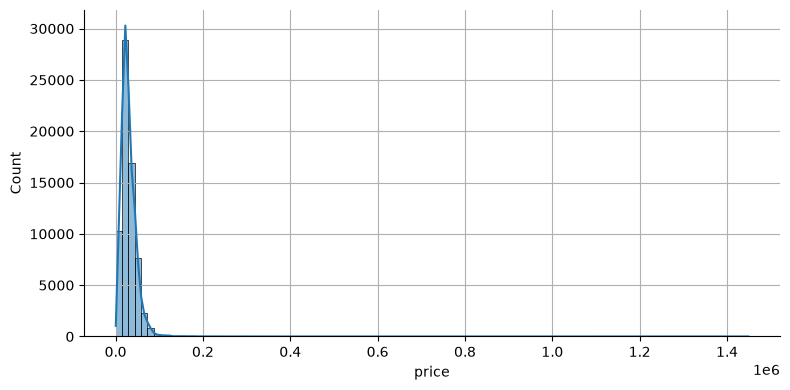

In [30]:
sns.displot(train['price'], bins=100, kde=True, height=4, aspect=2)
plt.grid()
pass

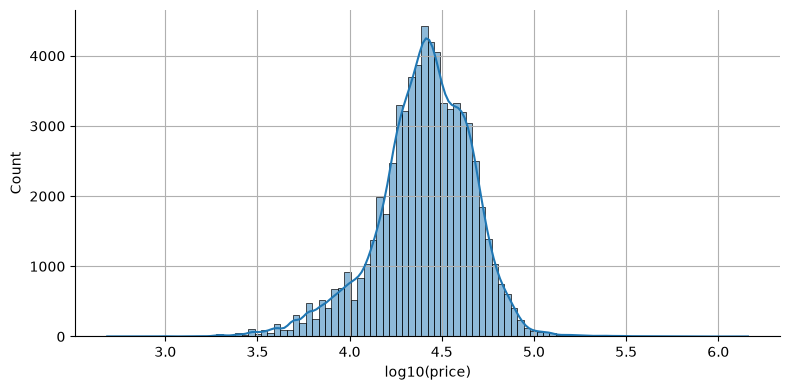

In [31]:
sns.displot(np.log10(train['price']), bins=100, kde=True, height=4, aspect=2)
plt.xlabel('log10(price)')
plt.grid()
pass

Распределение цены асимметричное, с тяжелым правым хвостом: основная масса — \$10–50 тыс., но встречаются машины за сотни тысяч долларов. В логарифмической шкале распределение близко к нормальному (с небольшим левым хвостом дешевых старых машин).

Следствие для моделей: ошибки на дорогих машинах в долларах будут большими, и RMSE будет в основном определяться ими.

### Цена в зависимости от года выпуска, пробега и мощности

Точек очень много, поэтому рисуем случайные 3000 (иначе все сливается):

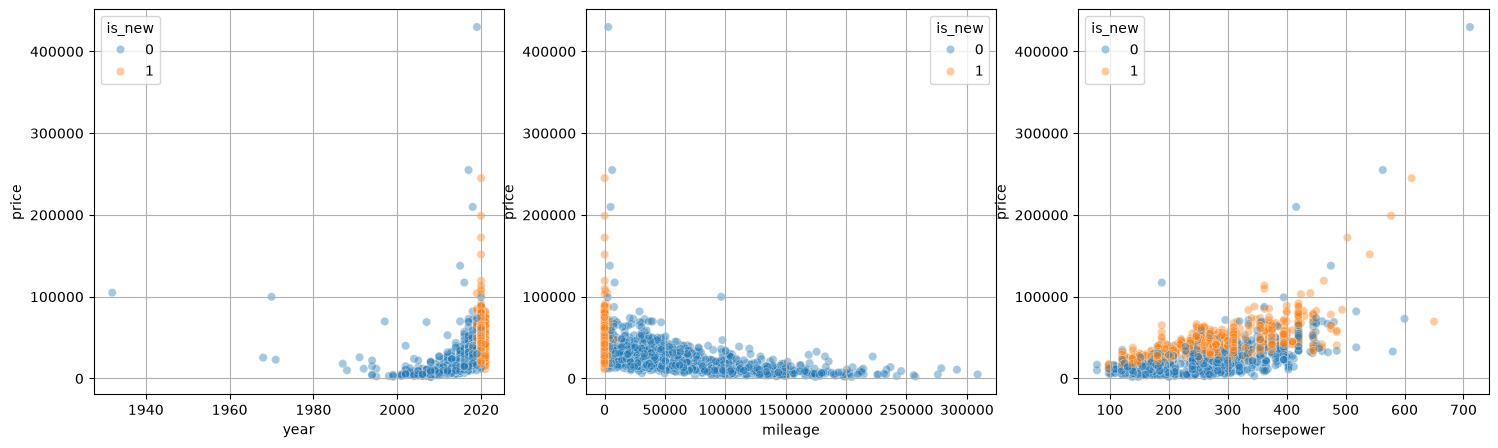

In [32]:
train_sample = train.sample(3000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x='year',       y='price', hue='is_new', data=train_sample, alpha=0.4, ax=axes[0])
sns.scatterplot(x='mileage',    y='price', hue='is_new', data=train_sample, alpha=0.4, ax=axes[1])
sns.scatterplot(x='horsepower', y='price', hue='is_new', data=train_sample, alpha=0.4, ax=axes[2])
for ax in axes: ax.grid()
pass

- **Год → цена**: чем новее машина, тем дороже, зависимость **нелинейная** (быстрый рост в последние годы). Старые машины (до ~1990 г.) выбиваются из общей картины: часть из них стоит дороже современных — это коллекционные автомобили.
- **Пробег → цена**: цена убывает с пробегом, примерно экспоненциально (быстрее всего — на первых 50 тыс. миль). Новые машины (оранжевые) образуют вертикальную полосу у нулевого пробега — с очень большим разбросом цен: пробег у них одинаковый, а цена определяется классом автомобиля.
- **Мощность → цена**: самая «линейная» и сильная зависимость: мощность — хороший индикатор класса машины (эконом / премиум / спорт). При одной и той же мощности новые машины заметно дороже подержанных.

На диаграммах рассеивания для всех пар признаков видна также сильная связь между самими признаками: год ↔ пробег, мощность ↔ объем двигателя, габариты ↔ расход топлива.

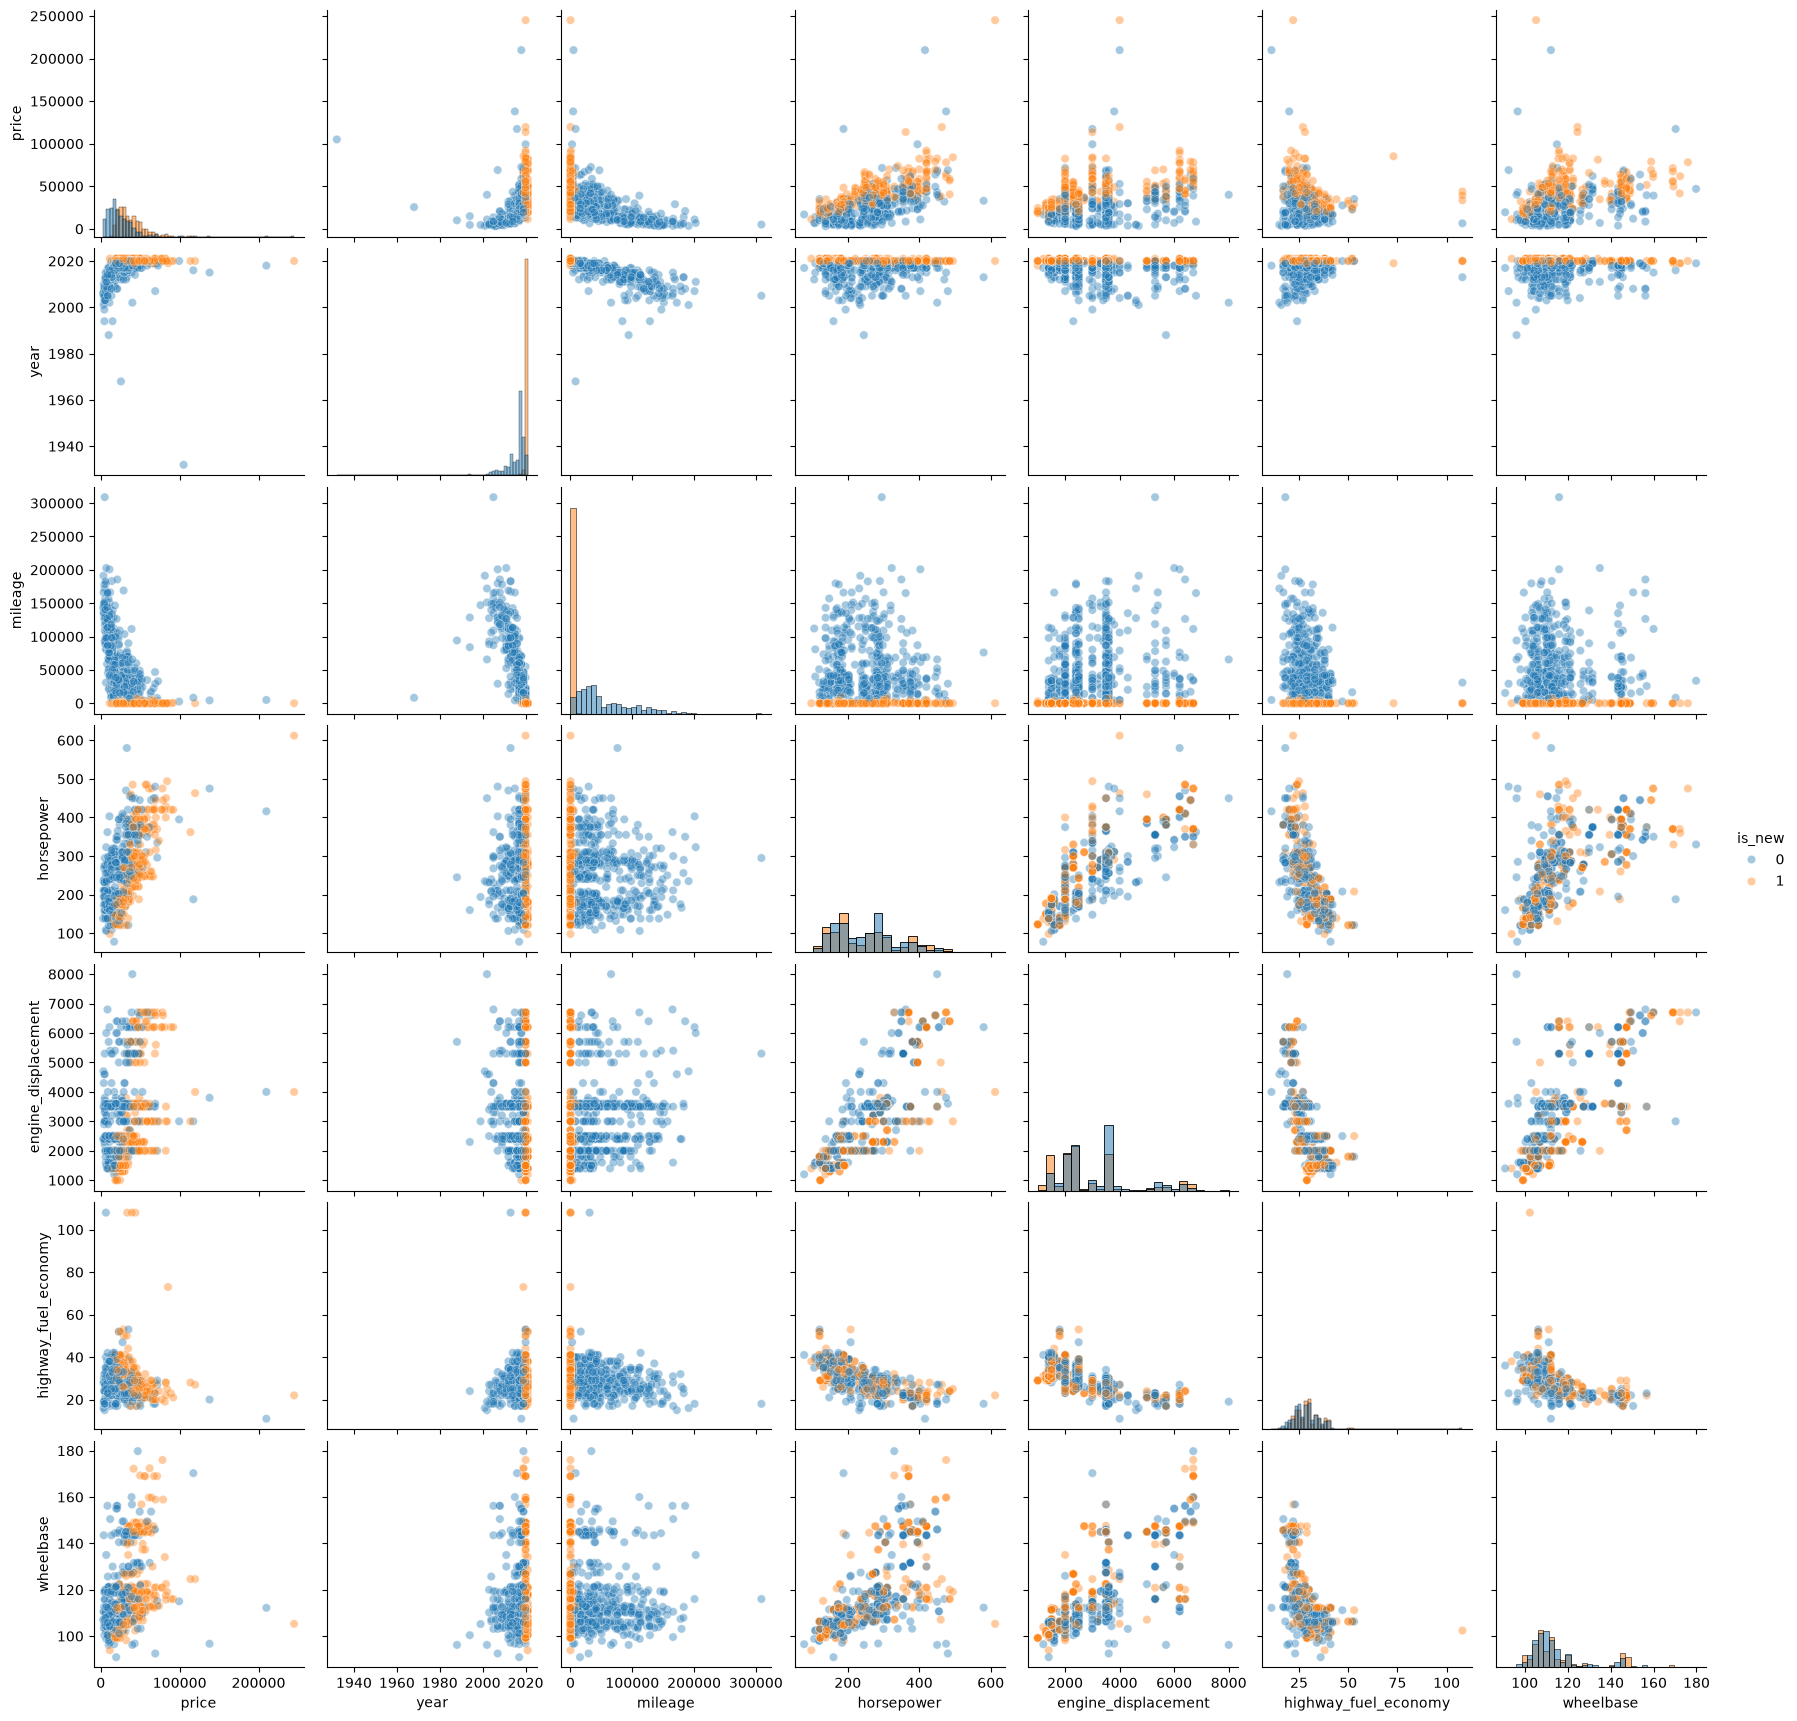

In [33]:
sns.pairplot(train_sample[['price', 'year', 'mileage', 'horsepower', 'engine_displacement',
                           'highway_fuel_economy', 'wheelbase', 'is_new']].sample(1000, random_state=42),
             hue='is_new', diag_kind='hist', plot_kws={'alpha': 0.4})
pass

### Категориальные признаки

Сколько раз номинальные переменные принимают то или иное значение:

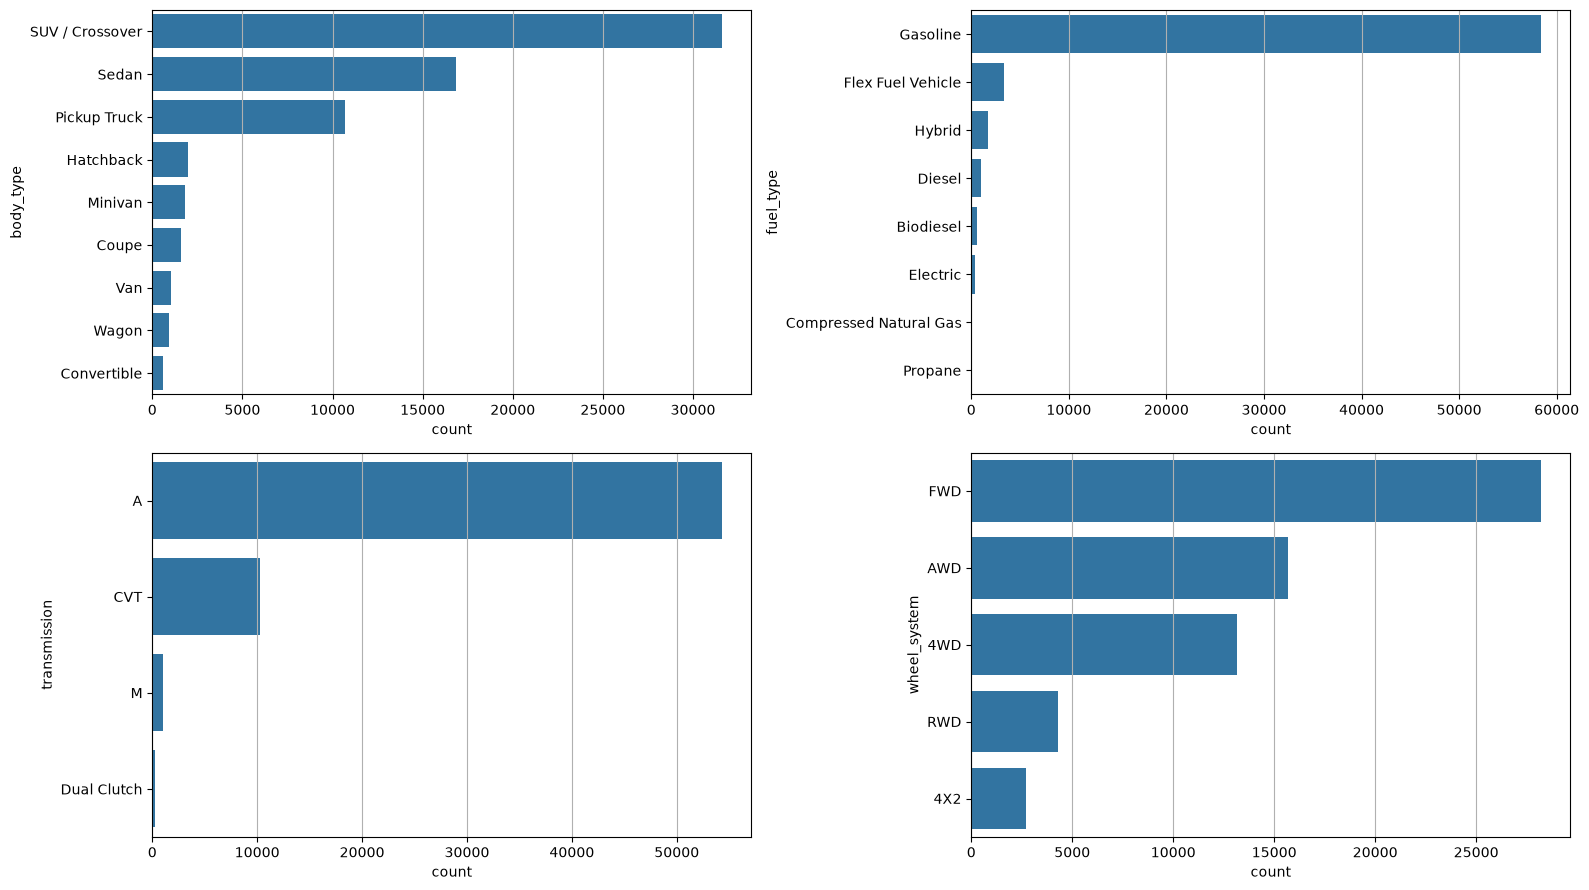

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, col in zip(axes.flat, ['body_type', 'fuel_type', 'transmission', 'wheel_system']):
    sns.countplot(y=col, order=train[col].value_counts().index, data=train, ax=ax)
    ax.grid(axis='x')
plt.tight_layout()
pass

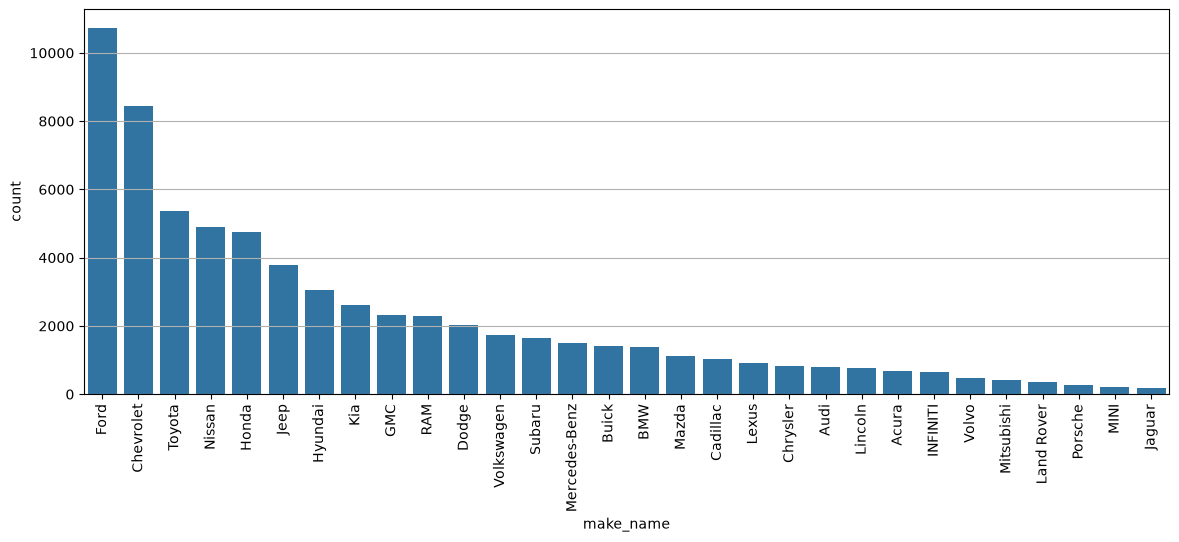

In [35]:
plt.figure(figsize=(14, 5))
sns.countplot(x='make_name', order=train['make_name'].value_counts().index[:30], data=train)
plt.xticks(rotation=90)
plt.grid(axis='y')
pass

In [36]:
train['make_name'].nunique(), (train['make_name'].value_counts() < 100).sum()

(60, np.int64(31))

Распределения категориальных признаков сильно неравномерные: доминируют кроссоверы и седаны, бензин, автомат, передний привод. Редкие категории (например, `Compressed Natural Gas`, `Dual Clutch`) встречаются считанные разы.

Из 60 марок 31 встречается меньше 100 раз (в основном экзотика: Ferrari, Lamborghini, Bentley, …). Это важно для кодирования (п. 6).

*Ящик с усами* (*бокс-диаграмма*): нижний и верхний концы ящика — 1-й и 3-й квартили, линия внутри — медиана, усы — до $1.5\times$ межквартильного расстояния, точки за усами — потенциальные выбросы.

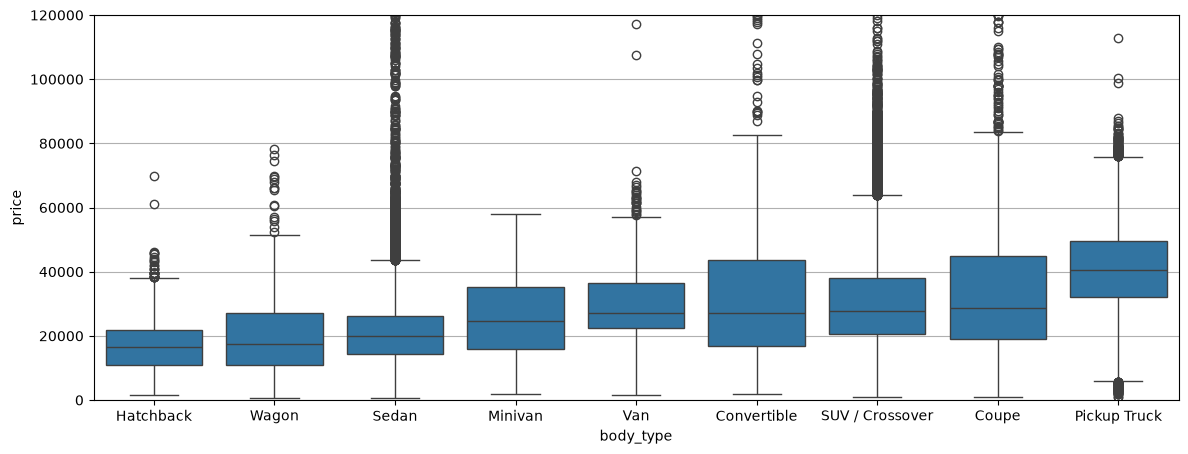

In [37]:
plt.figure(figsize=(14, 5))
sns.boxplot(x='body_type', y='price', data=train, order=train.groupby('body_type', observed=True)['price'].median().sort_values().index)
plt.ylim(0, 120_000)
plt.grid(axis='y')
pass

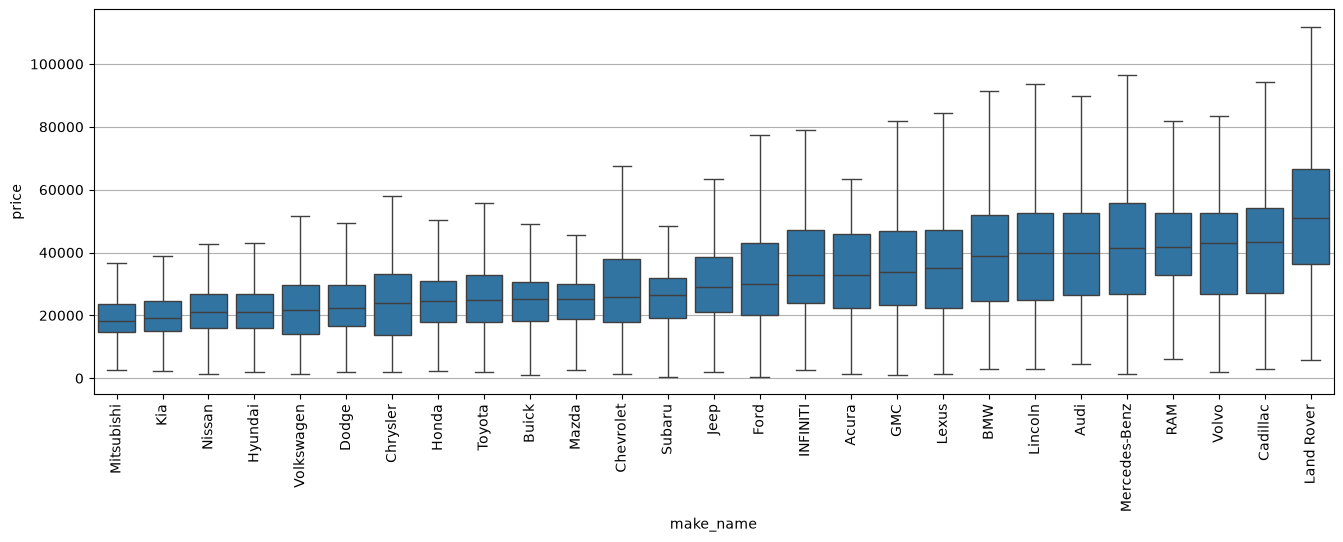

In [38]:
top_makes = train.groupby('make_name', observed=True)['price'].median()[train['make_name'].value_counts() >= 300].sort_values().index
plt.figure(figsize=(16, 5))
sns.boxplot(x='make_name', y='price', data=train[train['make_name'].isin(top_makes)], order=top_makes, showfliers=False)
plt.xticks(rotation=90)
plt.grid(axis='y')
pass

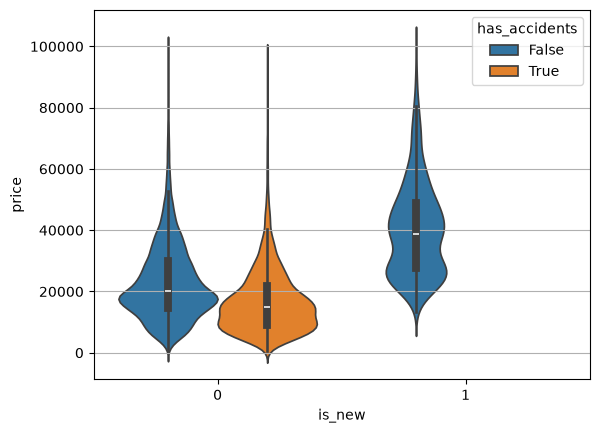

In [39]:
sns.violinplot(x='is_new', y='price', hue='has_accidents', data=train[train['price'] < 100_000], split=False)
plt.grid(axis='y')
pass

- **Тип кузова**: самые дорогие в среднем — пикапы (медиана ≈ \$40 тыс.), самые дешевые — хэтчбеки и универсалы (≈ \$17 тыс.). У седанов и кроссоверов огромное количество «выбросов» сверху — это премиальные марки, т.е. тип кузова сам по себе цену не определяет.
- **Марка**: медианная цена различается более чем вдвое — от ≈ \$18 тыс. (Mitsubishi, Kia) до ≈ \$50 тыс. (Land Rover). Внутри каждой марки разброс тоже очень большой (модельный ряд от компактов до флагманов).
- **Новая / подержанная и ДТП**: новые машины существенно дороже (медиана ≈ \$39 тыс. против ≈ \$20 тыс.), а среди подержанных побывавшие в ДТП дешевле. У новых машин `has_accidents` не заполнен вообще — поэтому для `is_new = 1` есть только одна «скрипка».

### Корреляционная матрица количественных признаков

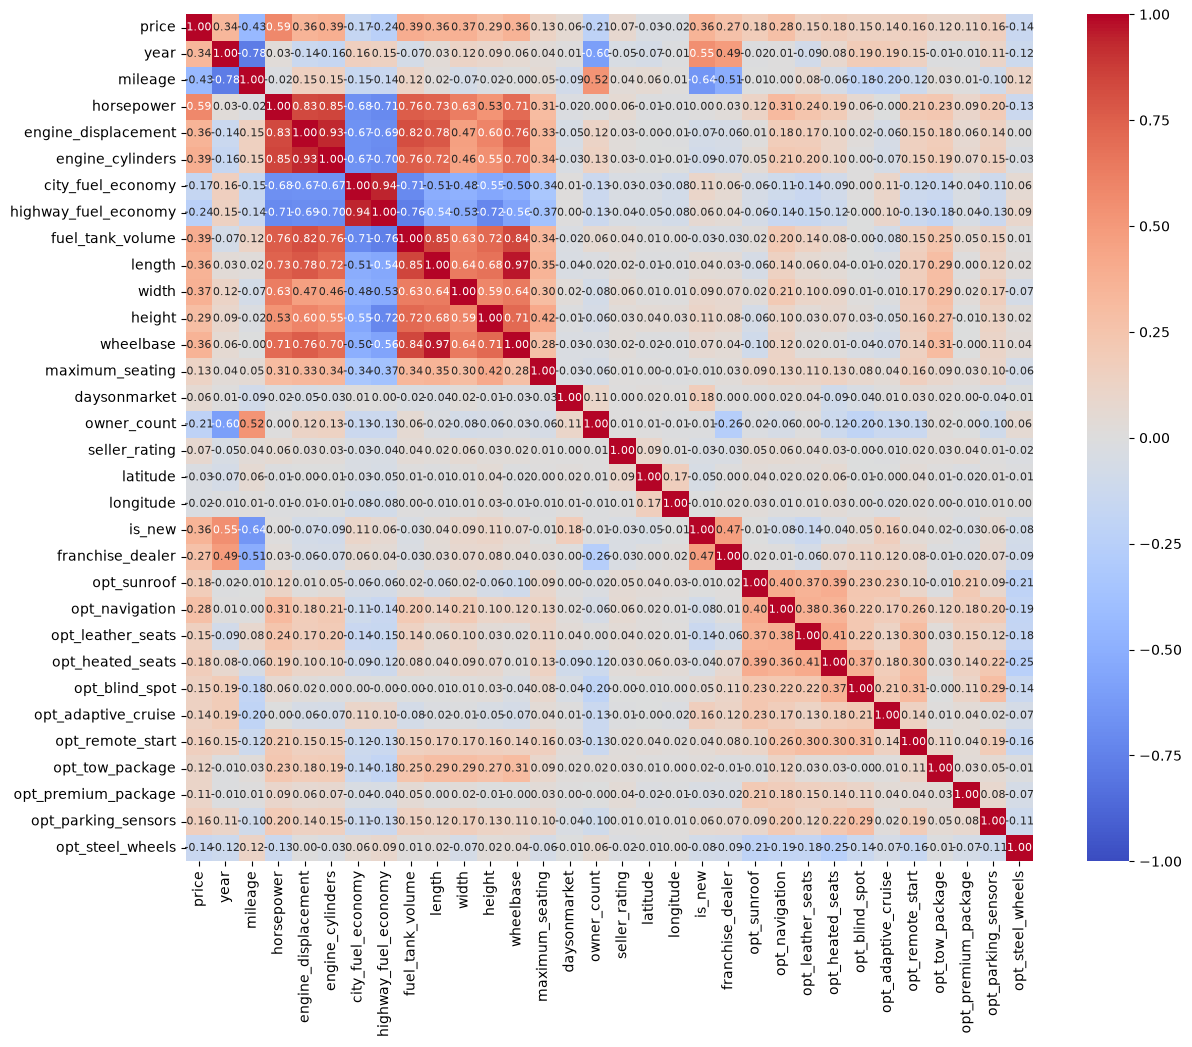

In [40]:
corr_mat = train.corr(numeric_only=True)
plt.figure(figsize=(14, 11))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', annot_kws={'size': 8})
pass

Корреляция признаков с ценой:

In [41]:
corr_mat['price'].drop('price').sort_values(key=np.abs, ascending=False)

horsepower              0.585892
mileage                -0.433964
fuel_tank_volume        0.394280
engine_cylinders        0.385076
width                   0.371202
length                  0.360057
wheelbase               0.359598
is_new                  0.357175
engine_displacement     0.357118
year                    0.341016
height                  0.292392
opt_navigation          0.277743
franchise_dealer        0.267511
highway_fuel_economy   -0.240140
owner_count            -0.214211
opt_sunroof             0.184212
opt_heated_seats        0.175330
city_fuel_economy      -0.165859
opt_parking_sensors     0.157788
opt_remote_start        0.157751
opt_leather_seats       0.151738
opt_blind_spot          0.147203
opt_adaptive_cruise     0.144781
opt_steel_wheels       -0.143784
maximum_seating         0.127125
opt_tow_package         0.116123
opt_premium_package     0.110669
seller_rating           0.071789
daysonmarket            0.059339
latitude               -0.027913
longitude 

Пары признаков с большой (по модулю) корреляцией:

In [42]:
corr_mat.where(np.triu(np.abs(corr_mat) > 0.7, k=1)).stack().dropna().sort_values(key=np.abs, ascending=False)

length                wheelbase               0.965451
city_fuel_economy     highway_fuel_economy    0.939566
engine_displacement   engine_cylinders        0.932220
horsepower            engine_cylinders        0.849768
fuel_tank_volume      length                  0.847045
                      wheelbase               0.842330
horsepower            engine_displacement     0.828422
engine_displacement   fuel_tank_volume        0.820103
                      length                  0.780456
year                  mileage                -0.777954
horsepower            fuel_tank_volume        0.764626
engine_cylinders      fuel_tank_volume        0.763634
highway_fuel_economy  fuel_tank_volume       -0.760066
engine_displacement   wheelbase               0.759664
horsepower            length                  0.734528
highway_fuel_economy  height                 -0.722338
engine_cylinders      length                  0.718554
fuel_tank_volume      height                  0.717334
height    

**Интерпретация корреляционной матрицы:**

- Сильнее всего с ценой связана **мощность** ($r \approx 0.59$), затем **пробег** ($r \approx -0.43$, чем больше пробег — тем дешевле), габариты и объем бака ($\approx 0.35$–$0.39$: большие машины дороже), `is_new` и `year`. Расход топлива связан с ценой отрицательно (экономичные машины — обычно небольшие и недорогие). Координаты продавца, рейтинг продавца и срок экспозиции с ценой практически не коррелируют ($|r| < 0.08$).
- Опции связаны с ценой слабее основных характеристик: сильнее всего навигация (`opt_navigation`, $r \approx 0.28$), остальные — $0.11$–$0.18$; стальные (не литые) диски — отрицательно ($r \approx -0.14$): это признак простой комплектации.
- Корреляция — мера только **линейной** связи. Например, связь цены с годом и пробегом сильнее, чем показывает $r$, но она нелинейная (см. диаграммы выше).
- Есть **группы сильно коррелированных признаков**, по сути описывающих одно и то же:
  - «размер машины»: `length`, `wheelbase`, `fuel_tank_volume`, `width`, `height` ($r$ до 0.97);
  - «двигатель»: `engine_displacement`, `engine_cylinders`, `horsepower` ($r$ до 0.93);
  - «расход»: `city_fuel_economy` и `highway_fuel_economy` ($r = 0.94$);
  - «возраст»: `year` и `mileage` ($r \approx -0.78$).

  Это ожидаемо физически (длинная машина имеет длинную колесную базу; больше цилиндров — больше объем).

# 4. Выбросы

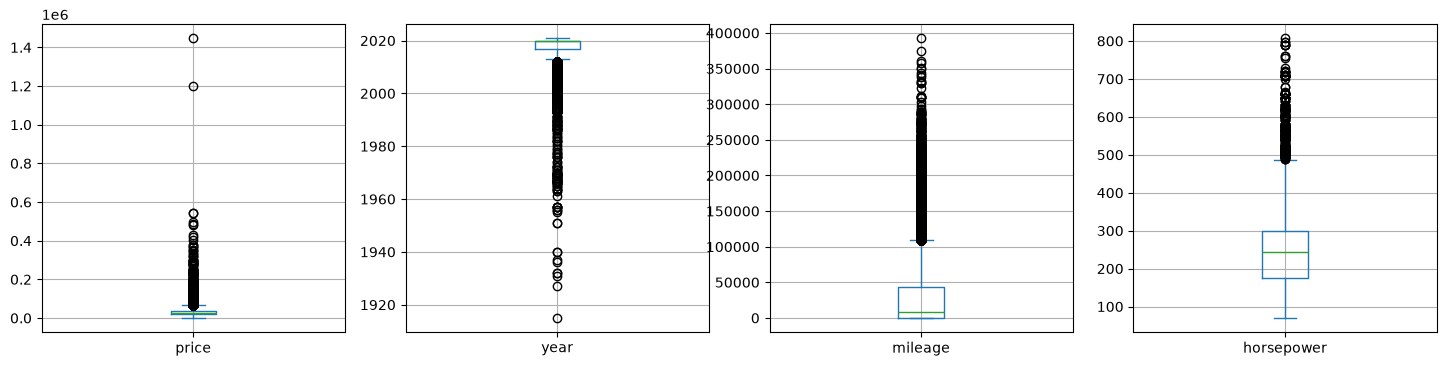

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['price', 'year', 'mileage', 'horsepower']):
    train[col].plot(kind='box', ax=ax)
    ax.grid()
pass

In [44]:
train['price'].quantile([0.001, 0.005, .01, .05, .25, .5, .75, .95, .99, .995, .999])

0.001      2169.92
0.005      3499.00
0.010      4499.76
0.050      8372.00
0.250     18495.00
0.500     26490.00
0.750     38190.00
0.950     59762.00
0.990     83492.72
0.995    104075.60
0.999    199995.00
Name: price, dtype: float64

In [45]:
train['year'].quantile([0.001, 0.005, .01, .05, .5])

0.001    1971.376
0.005    2001.000
0.010    2003.000
0.050    2010.000
0.500    2020.000
Name: year, dtype: float64

Посмотрим на самые дорогие и самые дешевые автомобили, а также на очень старые:

In [46]:
train.sort_values('price', ascending=False).head(10)[['price', 'year', 'make_name', 'body_type', 'mileage', 'horsepower', 'is_new']]

,price,year,make_name,body_type,mileage,horsepower,is_new
77977,1448880.0,2019,McLaren,Coupe,93.0,789.0,0
63189,1199500.0,2015,Chevrolet,Hatchback,123633.0,149.0,0
5279,545200.0,2020,Rolls-Royce,Sedan,30.0,563.0,1
39821,545150.0,2020,Rolls-Royce,Sedan,48.0,563.0,1
46606,495000.0,2020,Ferrari,Coupe,200.0,711.0,0
18697,488900.0,1997,Porsche,Coupe,7676.0,424.0,0
84926,479999.0,2019,Ferrari,Coupe,1159.0,711.0,0
44834,429900.0,2019,Ferrari,Coupe,3025.0,711.0,0
27154,420996.0,2020,Ferrari,Coupe,1573.0,711.0,0
46290,405675.0,2020,Rolls-Royce,Convertible,27.0,592.0,1


In [47]:
train.sort_values('price').head(10)[['price', 'year', 'make_name', 'body_type', 'mileage', 'horsepower', 'is_new']]

,price,year,make_name,body_type,mileage,horsepower,is_new
44151,484.0,2007,Ford,Sedan,171569.0,160.0,0
29422,498.0,2002,Subaru,Wagon,230324.0,212.0,0
31793,950.0,1996,Pontiac,Coupe,NaN,200.0,0
41355,995.0,2000,Pontiac,Sedan,231496.0,NaN,0
58226,999.0,1994,Buick,Sedan,240118.0,170.0,0
29145,1000.0,2004,GMC,SUV / Crossover,205725.0,NaN,0
22959,1000.0,2007,Ford,Pickup Truck,302950.0,300.0,0
41779,1000.0,2001,Ford,Pickup Truck,NaN,207.0,0
33200,1200.0,2005,Pontiac,Sedan,242812.0,205.0,0
26739,1250.0,2009,Chevrolet,Wagon,195423.0,155.0,0


In [48]:
train[train['year'] < 1990][['price', 'year', 'make_name', 'body_type', 'mileage', 'horsepower']].sample(10, random_state=1)

,price,year,make_name,body_type,mileage,horsepower
73652,14900.0,1970,Volkswagen,Hatchback,2800.0,NaN
89058,7990.0,1976,Mercedes-Benz,Sedan,138850.0,NaN
57885,9000.0,1989,Pontiac,Hatchback,96900.0,235.0
49252,17995.0,1985,GMC,Pickup Truck,19793.0,NaN
27502,36995.0,1963,Studebaker,Convertible,1412.0,NaN
33752,23495.0,1957,Pontiac,Sedan,NaN,NaN
58009,39995.0,1967,Buick,Coupe,51000.0,NaN
43379,64900.0,1969,Chevrolet,Coupe,NaN,NaN
18105,16995.0,1974,Pontiac,Convertible,73316.0,NaN
18599,97750.0,1961,Chevrolet,Coupe,94177.0,NaN


Попробуем эвристику Тьюки: выбросами считаются значения за пределами $[Q_1 - 1.5\,{\rm IQR},\ Q_3 + 1.5\,{\rm IQR}]$:

In [49]:
Q1, Q3 = train['price'].quantile([.25, .75])
IQR = Q3 - Q1
price_lower, price_upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
price_lower, price_upper, ((train['price'] < price_lower) | (train['price'] > price_upper)).mean()

(-11047.5, 67732.5, np.float64(0.02926814788429286))

**Что видим:**

- 99.8% цен лежат в диапазоне от ≈ \$2 200 до ≈ \$200 000 (квантили 0.1% и 99.9%).
- Самые дорогие машины в основном — настоящие суперкары и люкс (McLaren, Ferrari, Rolls-Royce). Но есть и явная **ошибка в данных**: Chevrolet-хэтчбек 2015 г. с пробегом 124 тыс. миль за \$1.2 млн (видимо, опечатка в цене).
- Самые дешевые (< \$1 000) — машины 1994–2007 гг. с пробегом 170–300 тыс. миль, цены похожи на символические/ошибочные.
- Автомобили старше 1990 г. — коллекционные/ретро (Studebaker 1963, Chevrolet 1961, …). Их цена определяется редкостью и состоянием, а не характеристиками; к тому же для них почти никогда не заполнены мощность и прочие характеристики.

**Эвристика Тьюки здесь не подходит**: она объявляет выбросами все машины дороже ≈ \$68 000 — это ≈ 3% выборки, и это вполне нормальные премиальные автомобили (BMW, Mercedes, Porsche, пикапы в топовой комплектации). Удаление их было бы ошибкой: модель потом не умела бы оценивать дорогие машины.

**Решение** — ограничим область применения модели массовым рынком:
- цена от \$1 000 до \$300 000 (отсекает ошибки и единичные гиперкары, для которых нет «соседей»);
- год выпуска не ранее 1990 (отсекает коллекционные автомобили).

Удаляется ≈ 0.2% объектов. Эти пороги — фиксированные числа, выбранные из смысла задачи, а не вычисленные по данным, поэтому их можно (и нужно) применить и к тестовой выборке: мы так определяем, *для каких автомобилей* строим модель, и качество проверяем на автомобилях из той же области.

In [50]:
def apply_bounds(df):
    return df[df['price'].between(1_000, 300_000) & (df['year'] >= 1990)]

print('train:', train.shape[0], '->', apply_bounds(train).shape[0])
print('test: ', test.shape[0],  '->', apply_bounds(test).shape[0])

train = apply_bounds(train)
test  = apply_bounds(test)

train: 67377 -> 67227
test:  22459 -> 22409


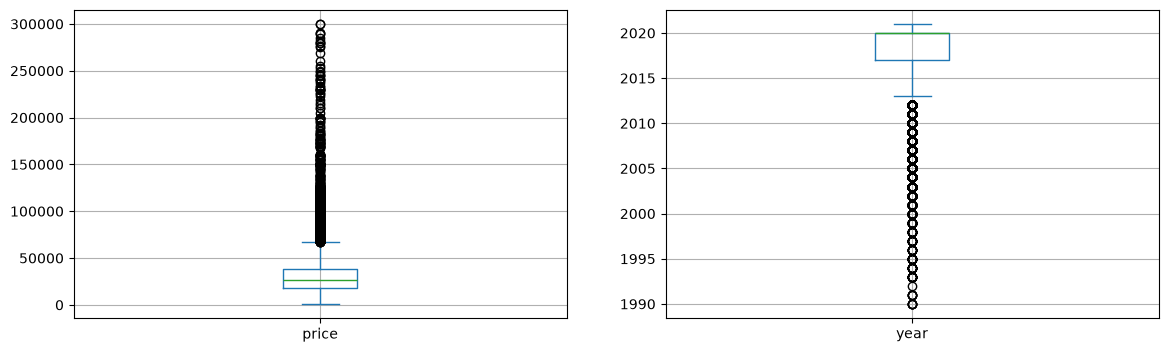

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train['price'].plot(kind='box', ax=axes[0]); axes[0].grid()
train['year'].plot(kind='box', ax=axes[1]);  axes[1].grid()
pass

# 5. Пропущенные значения

In [52]:
train.isna().sum()

price                       0
year                        0
mileage                  3115
horsepower               3802
engine_displacement      3802
engine_cylinders         2246
city_fuel_economy       10867
highway_fuel_economy    10867
fuel_tank_volume         3510
length                   3506
width                    3506
height                   3507
wheelbase                3506
maximum_seating          3506
daysonmarket                0
owner_count             33939
seller_rating             926
latitude                    0
longitude                   0
make_name                   0
body_type                 280
fuel_type                1841
transmission             1407
wheel_system             3246
is_new                      0
has_accidents           32010
frame_damaged           32010
fleet                   32010
salvage                 32010
franchise_dealer            0
opt_sunroof              4502
opt_navigation           4502
opt_leather_seats        4502
opt_heated

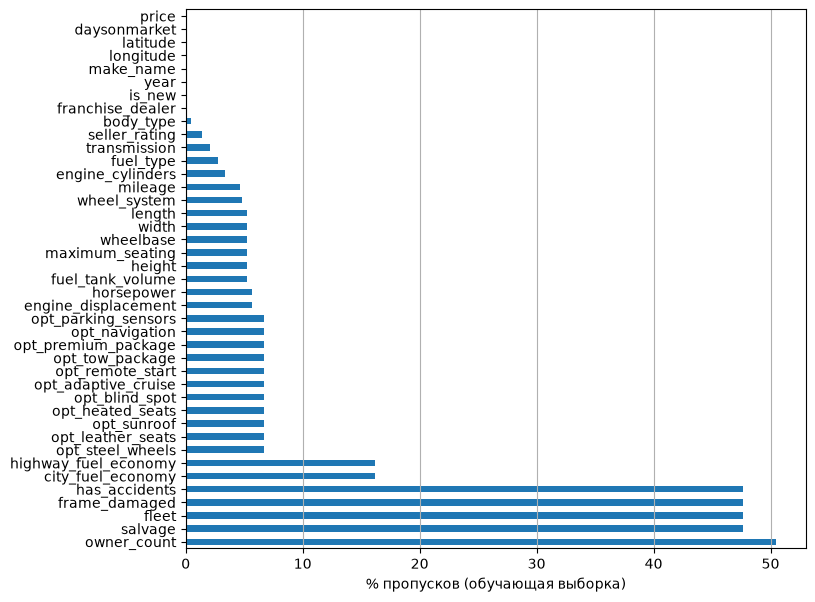

In [53]:
(train.isna().mean()*100).sort_values(ascending=False).plot(kind='barh', figsize=(8, 7))
plt.xlabel('% пропусков (обучающая выборка)')
plt.grid(axis='x')
pass

Пропуски распределены неслучайно. Посмотрим, как доля пропусков зависит от того, новый ли автомобиль:

In [54]:
train.groupby('is_new')[['mileage', 'owner_count', 'has_accidents', 'frame_damaged', 'fleet', 'salvage',
                     'opt_sunroof', 'city_fuel_economy', 'horsepower']] \
    .apply(lambda df: (df.isna().mean()*100).round(1))

,mileage,owner_count,has_accidents,frame_damaged,fleet,salvage,opt_sunroof,city_fuel_economy,horsepower
is_new,,,,,,,,,
0,0.9,2.8,0.1,0.1,0.1,0.1,4.2,15.5,3.6
1,8.5,100.0,96.9,96.9,96.9,96.9,9.3,16.9,7.7


In [55]:
train.groupby('is_new')['mileage'].describe()

,count,mean,std,min,25%,50%,75%,max
is_new,,,,,,,,
0,33919.0,58237.764704,47393.924126,50.0,24722.5,40984.0,83525.0,392998.0
1,30193.0,143.343192,1594.962576,0.0,2.0,5.0,10.0,231980.0


Отдельно разберемся с `owner_count`: он пропущен у всех новых машин, но у подержанных заполнен почти всегда. 

**Пропуски устроены неслучайно:**

- `owner_count` (число владельцев) пропущено у ≈ 50% объектов — у **всех** новых машин (владельцев у них не было, так что логично было бы заполнить нулем) и лишь у 3% подержанных. Среди подержанных признак на первый взгляд сильный. Но много владельцев бывает в первую очередь у старых машин с большим пробегом, но почти всю информацию о числе владельцев модель уже получает из `year` и `mileage`. **Удаляем столбец.**
- `has_accidents`, `frame_damaged`, `fleet`, `salvage` пропущены у 97% новых машин и у 0.1% подержанных: для новой машины истории просто нет. Заполнять модой (`False`) некорректно — это исказило бы смысл. **Вводим отдельную категорию `'unknown'`** — сам факт отсутствия информации информативен.
- `mileage` пропущен в основном у новых машин (8.5% против 0.9%), а у новых машин медианный пробег — 5 миль. **Для новых машин заполняем пробег нулем**, а не общей медианой (которая ≈ 8 000 миль и смешивает новые и подержанные).
- Опции `opt_*` пропущены у 9% новых и 4% подержанных машин — у объявления просто не заполнен список опций. Заполним их, как и остальные количественные признаки, медианой; для всех опций она равна 0, т.е. «опции нет».
- Остальные пропуски (характеристики двигателя, габариты, расход — у 3–17% объектов; тип кузова/топлива/привода — у 0.4–5%) — это просто отсутствие технических данных о комплектации. Их заполним стандартно — медианой/модой.



In [56]:
def fill_missing_by_rules(df):
    df = df.drop(columns=['owner_count'])
    # пропуск = информация об истории машины отсутствует (почти всегда у новых машин) -> отдельная категория
    for col in ['has_accidents', 'frame_damaged', 'fleet', 'salvage']:
        df[col] = df[col].astype(object).map({True: 'yes', False: 'no'}).fillna('unknown').astype('category')
    # у новой машины пробег практически нулевой
    df.loc[df['mileage'].isna() & (df['is_new'] == 1), 'mileage'] = 0
    return df

train = fill_missing_by_rules(train)
test  = fill_missing_by_rules(test)

train.isna().sum()

price                       0
year                        0
mileage                   306
horsepower               3802
engine_displacement      3802
engine_cylinders         2246
city_fuel_economy       10867
highway_fuel_economy    10867
fuel_tank_volume         3510
length                   3506
width                    3506
height                   3507
wheelbase                3506
maximum_seating          3506
daysonmarket                0
seller_rating             926
latitude                    0
longitude                   0
make_name                   0
body_type                 280
fuel_type                1841
transmission             1407
wheel_system             3246
is_new                      0
has_accidents               0
frame_damaged               0
fleet                       0
salvage                     0
franchise_dealer            0
opt_sunroof              4502
opt_navigation           4502
opt_leather_seats        4502
opt_heated_seats         4502
opt_blind_

Остальные пропуски (≤ 17%) заполним: количественные — **медианой**, категориальные — **самым частым значением** (модой). Медианы и моды вычисляются **по обучающей выборке** (`fit` на `X_train`), а затем применяются и к обучающей, и к тестовой (`transform`).



In [57]:
X_train = train.drop('price', axis=1)
y_train = train['price']
X_test  = test.drop('price', axis=1)
y_test  = test['price']

num_features = [col for col in X_train.columns if col not in cat_features]
num_features, cat_features

(['year',
  'mileage',
  'horsepower',
  'engine_displacement',
  'engine_cylinders',
  'city_fuel_economy',
  'highway_fuel_economy',
  'fuel_tank_volume',
  'length',
  'width',
  'height',
  'wheelbase',
  'maximum_seating',
  'daysonmarket',
  'seller_rating',
  'latitude',
  'longitude',
  'is_new',
  'franchise_dealer',
  'opt_sunroof',
  'opt_navigation',
  'opt_leather_seats',
  'opt_heated_seats',
  'opt_blind_spot',
  'opt_adaptive_cruise',
  'opt_remote_start',
  'opt_tow_package',
  'opt_premium_package',
  'opt_parking_sensors',
  'opt_steel_wheels'],
 ['make_name',
  'body_type',
  'fuel_type',
  'transmission',
  'wheel_system',
  'has_accidents',
  'frame_damaged',
  'fleet',
  'salvage'])

In [58]:
from sklearn.impute import SimpleImputer

imp_num = SimpleImputer(strategy='median')
imp_num.fit(X_train[num_features])
pd.Series(imp_num.statistics_, index=num_features)

year                    2020.000000
mileage                 4012.000000
horsepower               243.000000
engine_displacement     2500.000000
engine_cylinders           4.000000
city_fuel_economy         21.000000
highway_fuel_economy      29.000000
fuel_tank_volume          17.700000
length                   190.000000
width                     77.300000
height                    66.100000
wheelbase                111.200000
maximum_seating            5.000000
daysonmarket              35.000000
seller_rating              4.342857
latitude                  37.817600
longitude                -87.314800
is_new                     0.000000
franchise_dealer           1.000000
opt_sunroof                0.000000
opt_navigation             0.000000
opt_leather_seats          0.000000
opt_heated_seats           0.000000
opt_blind_spot             0.000000
opt_adaptive_cruise        0.000000
opt_remote_start           0.000000
opt_tow_package            0.000000
opt_premium_package        0

In [59]:
imp_cat = SimpleImputer(strategy='most_frequent')
imp_cat.fit(X_train[cat_features])
pd.Series(imp_cat.statistics_, index=cat_features)

make_name                   Ford
body_type        SUV / Crossover
fuel_type               Gasoline
transmission                   A
wheel_system                 FWD
has_accidents            unknown
frame_damaged                 no
fleet                    unknown
salvage                       no
dtype: str

In [60]:
X_train_num = pd.DataFrame(imp_num.transform(X_train[num_features]), columns=num_features, index=X_train.index)
X_train_cat = pd.DataFrame(imp_cat.transform(X_train[cat_features]), columns=cat_features, index=X_train.index)
X_train_num.isna().sum().sum(), X_train_cat.isna().sum().sum()

(np.int64(0), np.int64(0))

# 6. Категориальные признаки

Алгоритмы из scikit-learn (почти) не умеют работать с категориальными признаками напрямую — их надо закодировать числами.

- Бинарные `is_new`, `franchise_dealer` и опции `opt_*` уже закодированы 0/1.
- Небинарные номинальные признаки (`make_name`, `body_type`, `fuel_type`, `transmission`, `wheel_system`, а также `has_accidents`, `frame_damaged`, `fleet`, `salvage` — у них после п. 5 три значения: `yes`, `no`, `unknown`) кодируем **one-hot** (бинаризация): вместо признака с $m$ значениями вводим $m$ dummy-признаков 0/1.

Почему не просто пронумеровать значения (`Ford`→1, `BMW`→2, …)? Тогда появился бы ложный порядок и ложные расстояния: метод ближайших соседей считал бы, что `Ford` «ближе» к `BMW`, чем к `Toyota`, — это бессмыслица для номинального признака.

У признака `make_name` около 60 значений, многие из которых встречаются считанные разы (Ferrari, Lamborghini, …). Редкие марки (< 200 объектов в обучающей выборке) объединим в одну категорию `infrequent` — иначе получилось бы много почти всегда нулевых столбцов. Если в тестовой выборке встретится марка, которой не было в обучающей, она тоже попадет в `infrequent` (`handle_unknown='infrequent_if_exist'`).

In [61]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(min_frequency=200, handle_unknown='infrequent_if_exist', sparse_output=False)
enc.fit(X_train_cat)

dummies = pd.DataFrame(enc.transform(X_train_cat), columns=enc.get_feature_names_out(), index=X_train.index)
dummies.shape

(67227, 67)

In [62]:
dummies.head()

,make_name_Acura,make_name_Audi,make_name_BMW,make_name_Buick,make_name_Cadillac,make_name_Chevrolet,make_name_Chrysler,make_name_Dodge,make_name_Ford,make_name_GMC,make_name_Honda,make_name_Hyundai,make_name_INFINITI,make_name_Jeep,make_name_Kia,make_name_Land Rover,make_name_Lexus,make_name_Lincoln,make_name_MINI,make_name_Mazda,make_name_Mercedes-Benz,make_name_Mitsubishi,make_name_Nissan,make_name_Porsche,make_name_RAM,make_name_Subaru,make_name_Toyota,make_name_Volkswagen,make_name_Volvo,make_name_infrequent_sklearn,...,body_type_Van,body_type_Wagon,fuel_type_Biodiesel,fuel_type_Diesel,fuel_type_Electric,fuel_type_Flex Fuel Vehicle,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_infrequent_sklearn,transmission_A,transmission_CVT,transmission_Dual Clutch,transmission_M,wheel_system_4WD,wheel_system_4X2,wheel_system_AWD,wheel_system_FWD,wheel_system_RWD,has_accidents_no,has_accidents_unknown,has_accidents_yes,frame_damaged_no,frame_damaged_unknown,frame_damaged_yes,fleet_no,fleet_unknown,fleet_yes,salvage_no,salvage_unknown,salvage_yes
88910,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
79920,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
82754,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
8035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4784,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


# 7. Нормализация

Для метода ближайших соседей нормализация **обязательна**. kNN ищет ближайшие объекты по евклидову расстоянию
$$
\rho(x, x') = \sqrt{\sum_{j=1}^d (x_j - x'_j)^2},
$$
и признаки с большим масштабом полностью «забивают» остальные. Например, пробег меняется от 0 до ~400 000 миль, а число мест — от 2 до 15: разница пробегов в 1000 миль весит в расстоянии больше, чем разница между 2-местным купе и 8-местным минивэном. Без нормализации kNN по сути искал бы соседей только по пробегу (ниже, в п. 9, проверим это экспериментально).

Применим *стандартизацию*: $x_j \to (x_j - \overline{x}_j)/\sigma_j$ (нулевое среднее, единичное стандартное отклонение). Среднее и стандартное отклонение вычисляются по обучающей выборке.

Dummy-признаки (0/1) тоже стандартизуем — так все признаки вносят в расстояние сопоставимый вклад.

In [63]:
X_train_num.describe().loc[['mean', 'std', 'min', 'max']]

,year,mileage,horsepower,engine_displacement,engine_cylinders,city_fuel_economy,highway_fuel_economy,fuel_tank_volume,length,width,height,wheelbase,maximum_seating,daysonmarket,seller_rating,latitude,longitude,is_new,franchise_dealer,opt_sunroof,opt_navigation,opt_leather_seats,opt_heated_seats,opt_blind_spot,opt_adaptive_cruise,opt_remote_start,opt_tow_package,opt_premium_package,opt_parking_sensors,opt_steel_wheels
mean,2017.83108,29466.172431,247.620807,2938.252488,5.086587,22.416931,29.408021,18.557004,193.521182,78.334096,65.874646,115.109193,5.455219,75.117021,4.271408,36.981134,-90.715776,0.490904,0.812546,0.309132,0.340429,0.259717,0.398158,0.249691,0.154848,0.298392,0.043361,0.055275,0.173829,0.080191
std,3.62333,44469.048581,87.279697,1307.005364,1.450873,7.981562,7.050363,5.309271,19.622894,7.476735,7.353166,14.073976,1.143810,106.990800,0.511449,4.986815,13.969470,0.499921,0.390279,0.462139,0.473857,0.438483,0.489522,0.432838,0.361763,0.457556,0.203669,0.228519,0.378965,0.271591
min,1990.00000,0.000000,70.000000,700.000000,2.000000,8.000000,11.000000,1.900000,106.100000,61.400000,44.000000,73.500000,2.000000,0.000000,1.000000,18.443900,-123.205000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2021.00000,392998.000000,808.000000,8100.000000,12.000000,127.000000,127.000000,63.500000,290.000000,109.000000,117.600000,179.800000,15.000000,2067.000000,5.000000,48.886800,-66.078500,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [64]:
from sklearn.preprocessing import StandardScaler

X_train_enc = pd.concat((X_train_num, dummies), axis=1)

scaler = StandardScaler()
scaler.fit(X_train_enc)
X_train_scaled = pd.DataFrame(scaler.transform(X_train_enc), columns=X_train_enc.columns, index=X_train_enc.index)
X_train_scaled.describe().loc[['mean', 'std', 'min', 'max']]

,year,mileage,horsepower,engine_displacement,engine_cylinders,city_fuel_economy,highway_fuel_economy,fuel_tank_volume,length,width,height,wheelbase,maximum_seating,daysonmarket,seller_rating,latitude,longitude,is_new,franchise_dealer,opt_sunroof,opt_navigation,opt_leather_seats,opt_heated_seats,opt_blind_spot,opt_adaptive_cruise,opt_remote_start,opt_tow_package,opt_premium_package,opt_parking_sensors,opt_steel_wheels,...,body_type_Van,body_type_Wagon,fuel_type_Biodiesel,fuel_type_Diesel,fuel_type_Electric,fuel_type_Flex Fuel Vehicle,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_infrequent_sklearn,transmission_A,transmission_CVT,transmission_Dual Clutch,transmission_M,wheel_system_4WD,wheel_system_4X2,wheel_system_AWD,wheel_system_FWD,wheel_system_RWD,has_accidents_no,has_accidents_unknown,has_accidents_yes,frame_damaged_no,frame_damaged_unknown,frame_damaged_yes,fleet_no,fleet_unknown,fleet_yes,salvage_no,salvage_unknown,salvage_yes
mean,2.797822e-14,3.635841e-17,-8.413168e-17,1.335960e-16,6.130197e-18,1.906703e-16,-1.023109e-16,1.927841e-16,2.147683e-16,1.305521e-15,-6.326787e-16,-3.720396e-16,-5.178960e-17,-1.226039e-17,-4.785782e-16,-3.449821e-16,-1.486044e-15,2.113861e-17,-5.622871e-17,-2.494356e-17,-3.170792e-18,6.299306e-17,-5.200099e-17,7.081435e-17,-1.204901e-17,7.102574e-17,3.847227e-17,-4.861881e-17,1.147827e-16,-9.089603e-18,...,-8.244059e-18,2.705742e-17,-1.204901e-17,-1.965891e-17,-5.073267e-18,3.213069e-17,-3.614703e-17,8.032673e-18,2.748020e-18,-2.494356e-17,-5.284653e-17,-2.325247e-17,2.621188e-17,-2.705742e-17,3.339901e-17,-7.821286e-18,-7.187128e-18,1.109777e-17,-1.086525e-16,-8.328613e-17,2.890705e-17,8.117227e-17,-8.328613e-17,-3.889505e-17,-3.424455e-17,-8.328613e-17,-2.367525e-17,3.382178e-18,-8.328613e-17,1.944752e-17
std,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,...,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00,1.000007e+00
min,-7.681136e+00,-6.626270e-01,-2.035091e+00,-1.712517e+00,-2.127415e+00,-1.806293e+00,-2.610952e+00,-3.137366e+00,-4.455094e+00,-2.264922e+00,-2.974883e+00,-2.956485e+00,-3.020819e+00,-7.020938e-01,-6.396405e+00,-3.717277e+00,-2.325748e+00,-9.819704e-01,-2.081977e+00,-6.689200e-01,-7.184263e-01,-5.923132e-01,-8.133677e-01,-5.768751e-01,-4.280418e-01,-6.521483e-01,-2.128988e-01,-2.418875e-01,-4.586972e-01,-2.952664e-01,...,-1.259625e-01,-1.183744e-01,-9.165128e-02,-1.209957e-01,-7.509655e-02,-2.303356e-01,-2.930664e+00,-1.617974e-01,-5.454433e-03,-2.193619e+00,-4.255091e-01,-6.097244e-02,-1.236266e-01,-4.935440e-01,-2.042791e-01,-5.510970e-01,-9.382245e-01,-2.591909e-01,-8.958110e-01,-9.533814e-01,-2.921589e-01,-1.039189e+00,-9.533814e-01,-6.828347e-02,-8.391363e-01,-9.533814e-01,-3.527364e-01,-1.040863e+00,-9.533814e-01,-6.206874e-02
max,8.745944e-01,8.175001e+00,6.420547e+00,3.949323e+00,4.765036e+00,1.310318e+01,1.384222e+01,8.465066e+00,4.916682e+00,4.101540e+00,7.034486e+00,4.596518e+00,8.344785e+00,1.861747e+01,1.424576e+00,2.387447e+00,1.763665e+00,1.018361e+00,4.803126e-01,1.494947e+00,1.391931e+00,1.688296e+00,1.229456e+00,1.733478e+00,2.336220e+00,1.533394e+00,4.697067e+00,4.134154e+00,2.180087e+00,3.386773e+00,...,7.938874e+00,8.447775e+00,1.091092e+01,8.264756e+00,1.331619e+01,4.341490e+00,3.412196e-01,6.180568e+00,1.833371e+02,4.558676e-01,2.350126e+00,1.640085e+01,8.088871e+00,2.026162e+00,4.895264e+00,

### Собираем все шаги предобработки в `Pipeline`



In [65]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer

def make_preprocessor(num_features, cat_features, scale=True):
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'),
                              StandardScaler() if scale else 'passthrough'), num_features),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(min_frequency=200, handle_unknown='infrequent_if_exist', sparse_output=False),
                              StandardScaler() if scale else 'passthrough'), cat_features),
    ])

def make_model(model, num_features=num_features, cat_features=cat_features, scale=True):
    return Pipeline([('prep', make_preprocessor(num_features, cat_features, scale)), ('fit', model)])

# 8. Метод $k$ ближайших соседей (kNN)

Прогноз цены для автомобиля $x$ — среднее значение цены $k$ ближайших к нему (в пространстве признаков) автомобилей из обучающей выборки:
$$
\widehat{y}(x) = \frac{1}{k}\sum_{i \in N_k(x)} y^{(i)}.
$$

**Почему kNN подходит для этой задачи:**
- это ровно то, как люди оценивают машину на практике: «найди похожие объявления (та же марка, год, пробег, мощность, кузов) и посмотри, сколько за них просят» — метод очень интерпретируем: для любого прогноза можно показать $k$ машин-аналогов;
- метод **непараметрический** и не предполагает линейной зависимости. А зависимость цены от признаков явно нелинейная (см. EDA): цена падает с возрастом экспоненциально, влияние пробега на новые и старые машины разное, марка взаимодействует с мощностью и т.д. Линейная регрессия такие эффекты не уловит;
- данных много (≈67 тыс. объектов в обучающей выборке), а признаков относительно немного — в этой ситуации kNN работает хорошо;
- у метода всего один основной гиперпараметр — $k$, его легко подобрать кросс-валидацией.

Недостатки, которые мы учли: чувствительность к масштабу признаков (→ нормализация, п. 7), медленное предсказание на больших выборках (→ работаем с подвыборкой 3%).

Для начала обучим модель с $k=5$ (значение по умолчанию):

In [66]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

model = make_model(KNeighborsRegressor(n_neighbors=5))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('fit', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['year','mileage','horsepower',...,'opt_premium_package', 'opt_parking_sensors','opt_steel_wheels']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

In [67]:
y_train_predict = model.predict(X_train)
y_test_predict  = model.predict(X_test)

# 9. Ошибки на обучающей и тестовой выборках, выбор $k$

Метрики:
- $\rm RMSE = \sqrt{\frac1N\sum (y^{(i)} - \widehat y^{(i)})^2}$ — среднеквадратическая ошибка, в долларах; сильно штрафует большие промахи;
- $\rm MAE = \frac1N\sum |y^{(i)} - \widehat y^{(i)}|$ — средняя абсолютная ошибка, в долларах; «на сколько в среднем ошибаемся»;
- $R^2 = 1 - \frac{\rm RSS}{\rm TSS}$ — доля разброса цены, объясненная моделью (1 — идеально, 0 — не лучше константы);
- $\rm MAPE = \frac1N\sum \frac{|y^{(i)} - \widehat y^{(i)}|}{y^{(i)}}$ — средняя **относительная** ошибка (0.1 = ошибаемся в среднем на 10%).

Результаты всех моделей будем собирать в одну таблицу:

In [68]:
results = pd.DataFrame(columns=['RMSE train', 'RMSE test', 'MAE train', 'MAE test', 'R2 train', 'R2 test', 'MAPE test'])

def evaluate(name, y_train_predict, y_test_predict):
    results.loc[name, :] = (mean_squared_error(y_train, y_train_predict)**.5, mean_squared_error(y_test, y_test_predict)**.5,
                            mean_absolute_error(y_train, y_train_predict), mean_absolute_error(y_test, y_test_predict),
                            r2_score(y_train, y_train_predict), r2_score(y_test, y_test_predict),
                            mean_absolute_percentage_error(y_test, y_test_predict))
    return results.astype(float).round(3)

evaluate('kNN, k=5', y_train_predict, y_test_predict)

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158


При $k=5$: на тестовой выборке $R^2 \approx 0.87$ — модель объясняет 87% разброса цен. Средняя абсолютная ошибка ≈ \$3 700 при средней цене ≈ \$30 000 (≈ 12%).

Ошибка на обучающей выборке заметно меньше, чем на тестовой (RMSE ≈ \$5 350 против ≈ \$6 550). Для kNN это ожидаемо: при предсказании на обучающей выборке сам объект входит в число своих ближайших соседей (с расстоянием 0), т.е. модель частично «подсматривает» ответ. Поэтому ошибка на обучающей выборке для kNN — заниженная оценка, ориентироваться нужно на тестовую (или кросс-валидацию).

### Подбор $k$ кросс-валидацией

Значение $k$ нельзя подбирать по тестовой выборке (тогда тест перестанет быть «честным»). Используем 5-кратную кросс-валидацию на обучающей выборке: обучающая выборка делится на 5 частей, модель 5 раз обучается на 4 частях и проверяется на пятой; ошибки усредняются.

In [69]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 100])

grid = GridSearchCV(make_model(KNeighborsRegressor()), {'fit__n_neighbors': k_arr},
                    scoring='neg_root_mean_squared_error', cv=5, return_train_score=True, n_jobs=-1)
grid.fit(X_train, y_train)

grid.best_score_, grid.best_params_

(np.float64(-6956.875656408973), {'fit__n_neighbors': np.int64(3)})

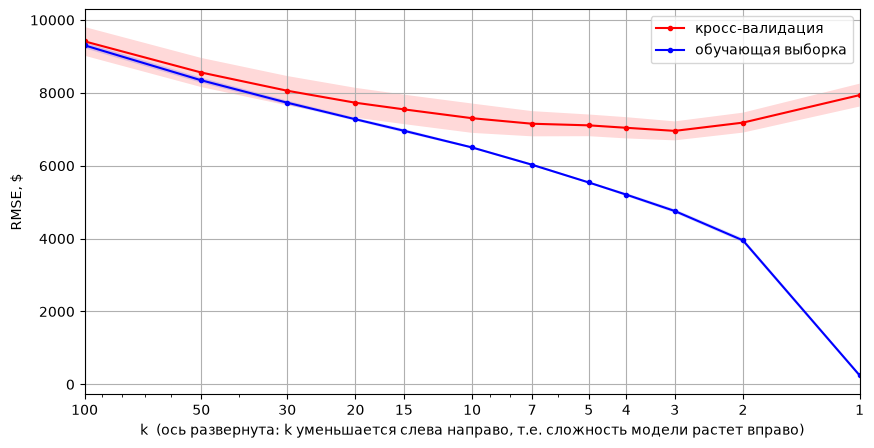

In [70]:
RMSE_cv_arr    = -grid.cv_results_['mean_test_score']
std_cv_arr     =  grid.cv_results_['std_test_score']
RMSE_train_arr = -grid.cv_results_['mean_train_score']
std_train_arr  =  grid.cv_results_['std_train_score']

plt.figure(figsize=(10, 5))
plt.plot(k_arr, RMSE_cv_arr, 'r.-', label='кросс-валидация')
plt.plot(k_arr, RMSE_train_arr, 'b.-', label='обучающая выборка')
plt.fill_between(k_arr, RMSE_cv_arr - std_cv_arr, RMSE_cv_arr + std_cv_arr, alpha=0.15, facecolor='red')
plt.fill_between(k_arr, RMSE_train_arr - std_train_arr, RMSE_train_arr + std_train_arr, alpha=0.15, facecolor='blue')
plt.xscale('log')
plt.xlim([max(k_arr), 1])
plt.xticks(k_arr, k_arr)
plt.xlabel('k  (ось развернута: k уменьшается слева направо, т.е. сложность модели растет вправо)')
plt.ylabel('RMSE, $')
plt.legend()
plt.grid()
pass

In [71]:
pd.DataFrame({'k': k_arr, 'RMSE train': RMSE_train_arr, 'RMSE CV': RMSE_cv_arr}).round(0)

,k,RMSE train,RMSE CV
0,1,247.0,7939.0
1,2,3951.0,7183.0
2,3,4758.0,6957.0
3,4,5207.0,7042.0
4,5,5541.0,7109.0
5,7,6027.0,7153.0
6,10,6501.0,7305.0
7,15,6961.0,7547.0
8,20,7276.0,7729.0
9,30,7730.0,8059.0


**Интерпретация графика** (сложность модели растет слева направо — чем меньше $k$, тем сложнее модель):

- $k=1$ — **переобучение**: на обучающей выборке ошибка почти нулевая (≈ \$250; не ровно 0, потому что в данных есть машины с одинаковыми признаками, но разными ценами — одна и та же модель у разных дилеров), а на кросс-валидации — ≈ \$7 900, хуже, чем при $k=3$.
- Большие $k$ (50–100) — **недообучение**: модель усредняет цены слишком многих и уже не очень похожих машин, ошибки на обучении и на кросс-валидации сближаются и обе растут (при $k=100$ RMSE ≈ \$9 400 — уровень линейной регрессии).
- **Оптимум** — $k=3$ (RMSE на кросс-валидации ≈ \$6 960). Впрочем, при $k$ от 3 до 5 ошибка различается всего на ≈ 2% (\$6 960–7 110) — кривая в этой области плоская.

Небольшое оптимальное $k$ означает, что у большинства машин в данных есть очень похожие «аналоги» (та же модель, год, комплектация), и усреднять по многим соседям не нужно.

Обучим модель с найденным оптимальным $k$ на всей обучающей выборке:

In [72]:
k_best = grid.best_params_['fit__n_neighbors']

knn_model = make_model(KNeighborsRegressor(n_neighbors=k_best))
knn_model.fit(X_train, y_train)

y_train_predict = knn_model.predict(X_train)
y_test_predict  = knn_model.predict(X_test)

evaluate(f'kNN, k={k_best}', y_train_predict, y_test_predict)

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159


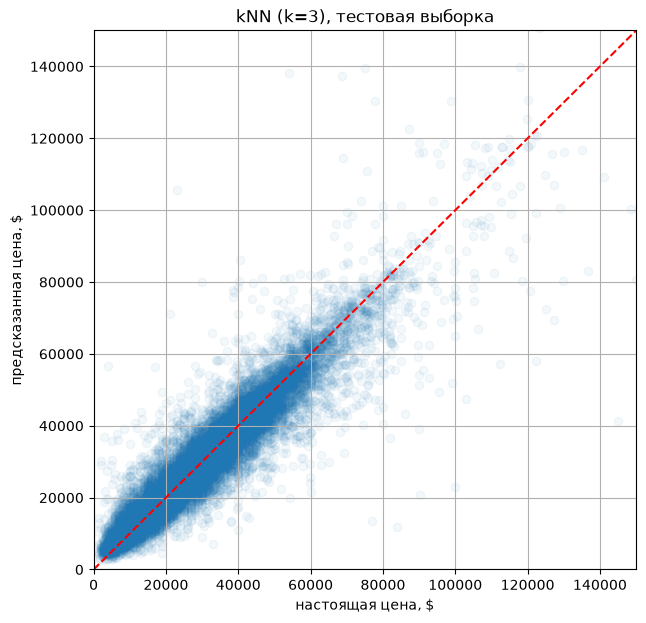

In [73]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_test_predict, alpha=0.05)
plt.plot([0, 150_000], [0, 150_000], 'r--')
plt.xlim(0, 150_000); plt.ylim(0, 150_000)
plt.xlabel('настоящая цена, $')
plt.ylabel('предсказанная цена, $')
plt.title(f'kNN (k={k_best}), тестовая выборка')
plt.grid()
pass

Относительная ошибка в зависимости от ценового диапазона (медиана $|y - \widehat y| / y$):

In [74]:
price_bins   = [0, 10_000, 20_000, 35_000, 60_000, np.inf]
price_labels = ['<10k', '10-20k', '20-35k', '35-60k', '>60k']

rel_err = (np.abs(y_test - y_test_predict) / y_test)
rel_err.groupby(pd.cut(y_test, price_bins, labels=price_labels), observed=True).median().round(3)

price
<10k      0.314
10-20k    0.116
20-35k    0.077
35-60k    0.074
>60k      0.088
Name: price, dtype: float64

**С оптимальным $k=3$**: на тесте RMSE ≈ \$6 600, MAE ≈ \$3 710, $R^2 \approx 0.86$ — практически так же, как при $k=5$ (RMSE ≈ \$6 550; разница в пределах шума, что согласуется с плоской кривой кросс-валидации). На обучающей выборке ошибка меньше (RMSE ≈ \$4 620, $R^2 \approx 0.93$) — небольшое переобучение, характерное для малых $k$.

На графике «предсказание — истина» точки ложатся вдоль диагонали; разброс в долларах растет с ценой. Дорогие машины (> \$80 000) модель систематически недооценивает — им трудно найти соседей, которые были бы еще дороже, и среднее по соседям «тянется» к центру.

Медианная **относительная** ошибка — около 7–12% для машин дороже \$10 000 и ≈ 31% для самых дешевых (< \$10 000). Дешевые машины — это старые машины с большим пробегом, их цена сильно зависит от состояния, которое в данных не отражено.

### Эксперимент: kNN без нормализации

Проверим утверждение из п. 7 — уберем `StandardScaler` (оставив заполнение пропусков и one-hot):

In [75]:
model = make_model(KNeighborsRegressor(n_neighbors=k_best), scale=False)
model.fit(X_train, y_train)
evaluate(f'kNN, k={k_best}, без нормализации', model.predict(X_train), model.predict(X_test))

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159
"kNN, k=3, без нормализации",6490.945,9714.944,3784.045,5555.104,0.866,0.706,0.227


**Без нормализации качество резко падает**: RMSE на тесте ≈ \$9 700 вместо ≈ \$6 600, $R^2$ — 0.71 вместо 0.86;. Как и ожидалось, без нормализации расстояние определяется в основном пробегом (масштаб — десятки тысяч) и объемом двигателя (тысячи), а марка, тип кузова, год и т.п. почти не учитываются. Нормализация для kNN необходима.

### Матрица рассогласования

Матрица рассогласования (confusion matrix) определена для задачи классификации, а у нас регрессия. Чтобы все же посмотреть, *какие* ошибки делает модель, разобьем цену на ценовые сегменты `<10k`, `10-20k`, `20-35k`, `35-60k`, `>60k` и сравним сегмент настоящей цены с сегментом предсказанной цены:

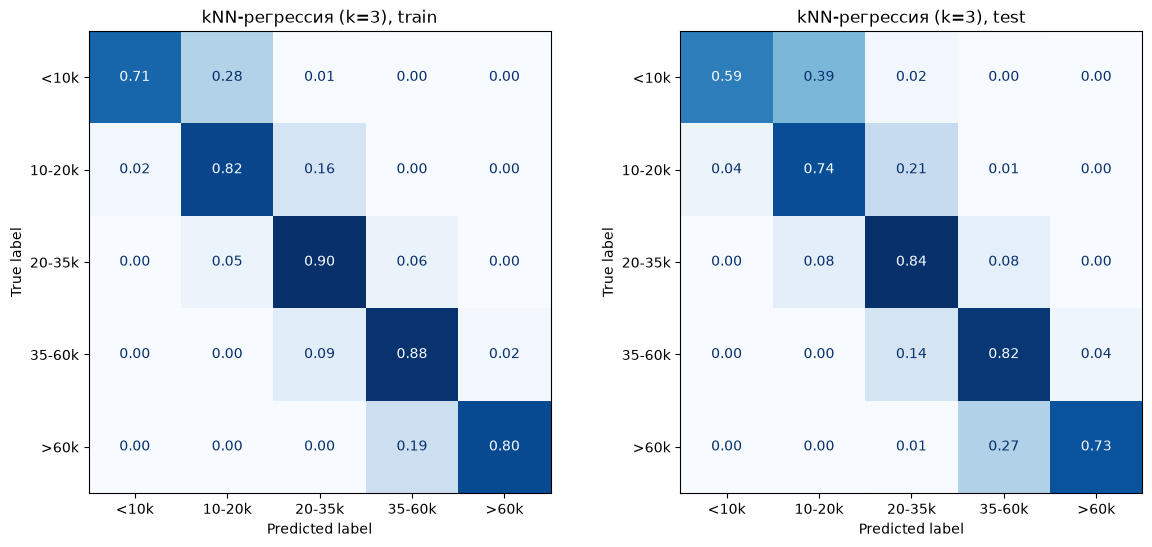

In [76]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion(y_true_cls, y_pred_cls, title, ax):
    ConfusionMatrixDisplay(confusion_matrix(y_true_cls, y_pred_cls, labels=price_labels, normalize='true'),
                           display_labels=price_labels).plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    ax.set_title(title)

to_segment = lambda price: pd.cut(price, price_bins, labels=price_labels).astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_confusion(to_segment(y_train), to_segment(y_train_predict), f'kNN-регрессия (k={k_best}), train', axes[0])
plot_confusion(to_segment(y_test),  to_segment(y_test_predict),  f'kNN-регрессия (k={k_best}), test',  axes[1])
pass

В клетке $(i, j)$ — доля автомобилей настоящего сегмента $i$, которые модель отнесла к сегменту $j$ (матрица нормирована по строкам, на диагонали — полнота *recall* для каждого сегмента).

Та же матрица в абсолютных числах (тестовая выборка):

In [77]:
pd.DataFrame(confusion_matrix(to_segment(y_test), to_segment(y_test_predict), labels=price_labels),
             index=['true ' + l for l in price_labels], columns=['pred ' + l for l in price_labels])

,pred <10k,pred 10-20k,pred 20-35k,pred 35-60k,pred >60k
true <10k,1054,692,41,6,0
true 10-20k,218,3761,1060,26,0
true 20-35k,6,711,7482,701,4
true 35-60k,0,9,807,4563,206
true >60k,0,2,6,283,771




- Матрица близка к диагональной: на тесте правильно определяется сегмент для большинства машин каждого сегмента.
- Все ошибки — **только в соседние сегменты**: машин, «перепутанных» через сегмент, практически нет (≈ 100 из 22 тыс., 0.4%). Это естественно: сегменты — соседние интервалы непрерывной цены, и ошибка в несколько тысяч долларов около границы сегмента переводит машину в соседний.
- Хуже всего определяются **крайние** сегменты: 41% дешевых (< \$10k) машин модель переоценивает (относит к \$10–20k), а 27% дорогих (> \$60k) — недооценивает. Это та самая «тяга к центру» у kNN: прогноз — среднее цен соседей, а у крайних объектов соседи в среднем ближе к центру распределения. Кроме того, крайние сегменты — самые малочисленные.
- На обучающей выборке диагональ заметнее, чем на тестовой (например, 0.71 против 0.59 для `<10k`) — проявление переобучения при малом $k$.


# 10. Другие модели

Сравним kNN с:
- **линейной регрессией** — простой параметрической моделью (baseline);
- **случайным лесом** (Random Forest) — ансамблем решающих деревьев;
- **градиентным бустингом** (`HistGradientBoostingRegressor`).

In [78]:
from sklearn.linear_model import LinearRegression

model = make_model(LinearRegression())
model.fit(X_train, y_train)
evaluate('Linear Regression', model.predict(X_train), model.predict(X_test))

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159
"kNN, k=3, без нормализации",6490.945,9714.944,3784.045,5555.104,0.866,0.706,0.227
Linear Regression,8968.249,9084.893,5400.773,5438.673,0.743,0.743,0.260


In [79]:
from sklearn.ensemble import RandomForestRegressor

rf_model = make_model(RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42))
rf_model.fit(X_train, y_train)
evaluate('Random Forest', rf_model.predict(X_train), rf_model.predict(X_test))

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159
"kNN, k=3, без нормализации",6490.945,9714.944,3784.045,5555.104,0.866,0.706,0.227
Linear Regression,8968.249,9084.893,5400.773,5438.673,0.743,0.743,0.260
Random Forest,2286.457,4765.560,1111.084,2495.909,0.983,0.929,0.095


In [80]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = make_model(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, random_state=42))
model.fit(X_train, y_train)
evaluate('Gradient Boosting', model.predict(X_train), model.predict(X_test))

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159
"kNN, k=3, без нормализации",6490.945,9714.944,3784.045,5555.104,0.866,0.706,0.227
Linear Regression,8968.249,9084.893,5400.773,5438.673,0.743,0.743,0.260
Random Forest,2286.457,4765.560,1111.084,2495.909,0.983,0.929,0.095
Gradient Boosting,3449.256,4417.058,2201.010,2520.098,0.962,0.939,0.095


**Сравнение моделей:**

| Модель | RMSE test | $R^2$ test | Комментарий |
|---|---|---|---|
| Linear Regression | ≈ 9 100 | 0.74 | ошибки на train и test почти равны — **недообучение**: линейная модель не может описать нелинейные зависимости (экспоненциальное падение цены с пробегом, взаимодействие марки и мощности и т.д.) |
| kNN, $k=3$ | ≈ 6 600 | 0.86 | заметно лучше линейной модели |
| Random Forest | ≈ 4 770 | 0.93 | лучше kNN; на train ошибка в 2 раза меньше, чем на test, — переобучение, но обобщает все равно хорошо |
| Gradient Boosting | ≈ 4 420 | **0.94** | лучшая модель |

Почему ансамбли деревьев лучше kNN? Деревья **сами отбирают** важные признаки: по графику важности основную роль играют мощность (≈ 46%), пробег (≈ 24%) и год (≈ 5%). А kNN считает расстояние по всем ≈ 100 признакам (включая 67 dummy-столбцов) с **одинаковыми весами**: слабо связанные с ценой признаки (координаты, рейтинг продавца, срок экспозиции) вносят в расстояние столько же, сколько мощность, и «зашумляют» поиск соседей.

# Итоговая таблица

In [81]:
results.astype(float).round(3).sort_values('RMSE test')

,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test,MAPE test
Gradient Boosting,3449.256,4417.058,2201.010,2520.098,0.962,0.939,0.095
Random Forest,2286.457,4765.560,1111.084,2495.909,0.983,0.929,0.095
"kNN, k=5",5352.632,6547.676,2928.154,3668.841,0.909,0.866,0.158
"kNN, k=3",4618.289,6599.907,2525.074,3707.691,0.932,0.864,0.159
Linear Regression,8968.249,9084.893,5400.773,5438.673,0.743,0.743,0.260
"kNN, k=3, без нормализации",6490.945,9714.944,3784.045,5555.104,0.866,0.706,0.227


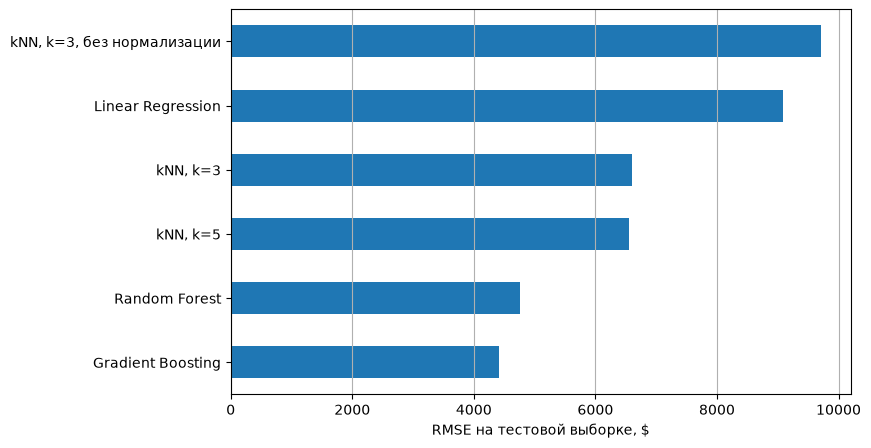

In [82]:
results.astype(float)['RMSE test'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.xlabel('RMSE на тестовой выборке, $')
plt.grid(axis='x')
pass

# 13. Выводы

1. **Задача**: предсказать цену автомобиля в США по его характеристикам (регрессия). Использована случайная подвыборка 3% (≈ 90 тыс. объявлений) из 3 млн, т.к. полный файл велик(10 ГБ) , а для kNN это и не нужно.

2. **Данные**: цена сильно скошена вправо (медиана ≈ \$26 500, хвост до \$1.4 млн); почти половина объявлений — новые машины. Сильнее всего цена связана с мощностью, пробегом, годом и маркой; координаты и рейтинг продавца почти не влияют. Много сильно коррелированных групп признаков (габариты, двигатель, расход, возраст).

3. **Предобработка**:
   - выбросы — отфильтрованы по смысловым правилам (цена \$1 000–300 000, год ≥ 1990, ≈ 0.2% данных); эвристика Тьюки не подошла бы — она удаляет нормальные премиальные машины;
   - отбор столбцов — по доле пропусков, смыслу и влиянию на цену внутри одной модели и года: добавлены признаки истории `fleet`, `salvage` и 11 опций из `major_options`; отброшены, в частности, цвет (на цену не влияет), `isCab` (дубль `fleet`) и текст объявления `description`;
   - пропуски — оказались неслучайными (связаны с тем, что машина новая): `owner_count` удален (число владельцев почти полностью определяется годом и пробегом), для `has_accidents`/`frame_damaged`/`fleet`/`salvage` введена категория `unknown`, пробег новых машин заполнен нулем, остальное — медианой/модой по обучающей выборке;
   - категориальные признаки — one-hot, редкие марки объединены;
   - нормализация (стандартизация) — **необходима** для kNN.

4. **kNN**: оптимальное число соседей по кросс-валидации — $k=3$ (при $k$ от 3 до 5 качество почти одинаковое). На тестовой выборке RMSE ≈ \$6 600, MAE ≈ \$3 710, $R^2 \approx 0.86$; типичная относительная ошибка — 7–12% для машин дороже \$10 000. При $k=1$ модель переобучается, при больших $k$ — недообучается. Модель недооценивает самые дорогие и переоценивает самые дешевые машины («тяга к центру»), что хорошо видно на матрице рассогласования по ценовым сегментам: ошибки только в соседние сегменты, хуже всего — крайние сегменты.

5. **Сравнение моделей** (RMSE / $R^2$ на тесте): линейная регрессия ≈ \$9 100 / 0.74 (недообучение) < **kNN ≈ \$6 600 / 0.86** < случайный лес ≈ \$4 770 / 0.93 < градиентный бустинг ≈ \$4 420 / **0.94**. Ансамбли деревьев лучше kNN, т.к. сами отбирают важные признаки, тогда как kNN учитывает все признаки в расстоянии с равными весами.

**Возможные улучшения**: использовать модель автомобиля `model_name`; подобрать веса признаков для kNN или использовать `weights='distance'`; обучить на большей части датасета.